# Домашнее задание 1: рекомендательные системы

**Козлов Кирилл Андреевич** · Amazon Reviews 2018 Video Games 5-core

ItemKNN, iALS, EASE, FM и timeSVD++ с нуля. Версия v2: признаки FM рассчитаны по истории до запроса.
[Внешняя оценка за 2019 год на Amazon Reviews 2023](external_2019/experiments.ipynb) использует те же гиперпараметры.


### 1. Источник и запуск

[Открыть в Google Colab](https://colab.research.google.com/github/noobmaster-ru/recsys_cmc_msu_2026_course/blob/2a036b40abbd65d2a562cf0294ec2dcc9f71a703/homework_1/experiments.ipynb) → «Среда выполнения → Выполнить всё». Достаточно CPU.
Первая ячейка скачает репозиторий и данные, установит недостающие зависимости.
Данные и отчёты берутся из зафиксированной ревизии `3cb3e93`; текущие версии библиотек показаны ниже.

«Выполнить всё» пересчитывает EDA и показывает **сохранённые результаты моделей**, без нового обучения.
Пересчитанные статистики и разбиение сверяются с отчётами.
Полное обучение с подбором запускается отдельно: `python scripts/reproduce.py --output ../../recsys-reproduction`.

Локально: `pip install -r requirements.txt`, затем `python scripts/prepare_data.py --download`
из `homework_1/`. Рендер модельных разделов без данных: `python scripts/execute_notebook.py --section reports`.

[Amazon Reviews 2018 Video Games](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/):
`Video_Games_5.json.gz` и `meta_Video_Games.json.gz`. Контрольные суммы проверяются при загрузке.

| Поле | Смысл |
|---|---|
| `user_id`, `item_id` | ID пользователя и ASIN товара |
| `rating` | Оценка от 1 до 5 |
| `timestamp` | Дата публикации, Unix seconds, UTC |
| `title`, `brand`, `categories` | Название, бренд и категории карточки |
| `description`, `features` | Описание и характеристики |

Отзыв не равен покупке. Карточки и тексты используются только в EDA;
FM получает признаки из fit IDs/timestamps до запроса. Test уже оценивался в v1:
результаты v2 — корректирующая повторная оценка того же holdout.


In [1]:
"""Notebook startup for Colab; no model training or changes to published evidence."""
from pathlib import Path
import hashlib
import importlib.metadata
import importlib.util
import json
import os
import subprocess
import sys

COLAB_REPOSITORY = 'https://github.com/noobmaster-ru/recsys_cmc_msu_2026_course.git'
COLAB_BASE_COMMIT = '3cb3e93bed3fb789ed01c9035a36643d2fbc4076'


def in_google_colab():
    if 'google.colab' in sys.modules or os.environ.get('COLAB_RELEASE_TAG'):
        return True
    try:
        return importlib.util.find_spec('google.colab') is not None
    except (ModuleNotFoundError, ValueError):
        return False


def local_homework_root(working=None):
    working = Path.cwd() if working is None else Path(working)
    return next((p for p in [working, working / 'homework_1', working / 'recsys' / 'homework_1']
                 if (p / 'scripts/prepare_data.py').is_file()), None)


def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def ensure_colab_workspace(base=Path('/content')):
    """Use a separate pinned checkout; never reset or overwrite another project."""
    base = Path(base)
    checkout = base / ('recsys_hw1_' + COLAB_BASE_COMMIT[:8])
    if not checkout.exists():
        base.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'clone', '--no-checkout', COLAB_REPOSITORY, str(checkout)], check=True)
        subprocess.run(['git', '-C', str(checkout), 'checkout', '--detach', COLAB_BASE_COMMIT], check=True)
    actual = subprocess.check_output(['git', '-C', str(checkout), 'rev-parse', 'HEAD'], text=True).strip()
    if actual != COLAB_BASE_COMMIT:
        raise RuntimeError('The dedicated Colab checkout has another revision; use a fresh runtime.')
    # Keep the Colab kernel and preloaded numerical libraries. Install only missing packages.
    requirements = {'numpy': 'numpy>=1.26,<3', 'scipy': 'scipy>=1.11,<2',
                    'pandas': 'pandas>=2.2,<3', 'matplotlib': 'matplotlib>=3.8,<4',
                    'nbformat': 'nbformat>=5.10,<6', 'nbclient': 'nbclient>=0.10,<1',
                    'ipykernel': 'ipykernel>=6,<8'}
    missing = []
    for package, requirement in requirements.items():
        try:
            importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            missing.append(requirement)
    if missing:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', *missing], check=True)
    root = checkout / 'homework_1'
    audit = json.loads((root / 'reports/data_audit.json').read_text())
    ready = all((root / rel).is_file() and file_sha256(root / rel) == info['sha256']
                for rel, info in audit['outputs'].items())
    if not ready:
        print('Downloading and preparing Amazon Reviews 2018 (about 200 MB)...', flush=True)
        subprocess.run([sys.executable, str(root / 'scripts/prepare_data.py'), '--download'], cwd=root, check=True)
    for rel, info in audit['outputs'].items():
        if file_sha256(root / rel) != info['sha256']:
            raise ValueError('Prepared data differ from the published dataset: ' + rel)
    os.chdir(root)
    print('Colab ready: EDA and published model results. Full retraining is a separate command.', flush=True)
    return root


def preserve_or_create_report(path, payload):
    """Validate existing data statistics, retain published runtime-version metadata."""
    path = Path(path)
    if path.exists():
        saved = json.loads(path.read_text())
        current = json.loads(json.dumps(payload, ensure_ascii=False))
        # EDA statistics must match; package versions describe different runtimes.
        if path.name == 'eda_summary.json':
            saved = {k: v for k, v in saved.items() if k != 'library_versions'}
            current = {k: v for k, v in current.items() if k != 'library_versions'}
        if saved != current:
            raise ValueError('Recomputed data/protocol differ from the published report: ' + path.name)
    else:
        path.write_text(json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True) + '\n', encoding='utf-8')

if in_google_colab() and local_homework_root() is None:
    ensure_colab_workspace()

from pathlib import Path
import os, sys, json, gzip, hashlib, math, random, textwrap
from collections import Counter
import importlib.metadata

_working = Path.cwd()
ROOT = next((p for p in [_working, _working/'homework_1', _working/'recsys'/'homework_1']
             if (p/'scripts/prepare_data.py').is_file()), None)
assert ROOT is not None, 'Запустите notebook из homework_1 или корня репозитория'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
sys.path.insert(0, str(ROOT))
from scripts.prepare_data import deterministic_gzip, sha256

SEED = 42
K = 10
RELEVANCE_THRESHOLD = 4
VALIDATION_START = pd.Timestamp('2016-01-01', tz='UTC')
TEST_START = pd.Timestamp('2017-01-01', tz='UTC')
random.seed(SEED)
np.random.seed(SEED)
FIGURES = ROOT / 'reports/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
COLORS = ['#255F85', '#D87535', '#3B8C78', '#9274A6', '#6B7C8F']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.axisbelow': True,
    'savefig.dpi': 145,
})
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

def show_figure(name, fig):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def fmt(value):
    return f'{value:,}'.replace(',', ' ')

versions = {name: importlib.metadata.version(name) for name in
            ['numpy', 'scipy', 'pandas', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versions, name='Версия').to_frame())
from scripts.reporting import load_validation_report, load_final_report
_saved_protocol=json.loads((ROOT/'reports/evaluation_protocol.json').read_text())
validation_view={'stats':_saved_protocol['evaluation_diagnostics']['validation']}


Matplotlib is building the font cache; this may take a moment.


,Версия
numpy,2.2.4
scipy,1.15.2
pandas,2.2.3
matplotlib,3.10.1
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


In [2]:
audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
for relative, info in audit['outputs'].items():
    path = ROOT / relative
    assert path.is_file(), 'Сначала выполните python scripts/prepare_data.py --download'
    assert sha256(path) == info['sha256'], f'Изменился файл: {relative}'

interactions = pd.read_csv(ROOT / 'data/processed/interactions.csv.gz',
    dtype={'user_id': 'string', 'item_id': 'string', 'rating': 'int8', 'timestamp': 'int64'})
interactions['datetime'] = pd.to_datetime(interactions['timestamp'], unit='s', utc=True)
with gzip.open(ROOT / 'data/processed/items.jsonl.gz', 'rt', encoding='utf-8') as stream:
    items = pd.DataFrame(json.loads(line) for line in stream)
items['item_id'] = items['item_id'].astype('string')
assert not interactions.duplicated(['user_id', 'item_id']).any()
assert not items.item_id.duplicated().any()
assert set(interactions.item_id) == set(items.item_id)
assert interactions[['user_id', 'item_id', 'rating', 'timestamp']].notna().all().all()
assert interactions.rating.between(1, 5).all()
assert len(interactions) == audit['cleaned']['interactions']
print('Контрольные суммы, уникальность пар и связь с метаданными проверены.')

Контрольные суммы, уникальность пар и связь с метаданными проверены.


### 2. Очистка и границы выборки

Оставлена самая ранняя user–item пара; ties разрешены порядком строк. Для ASIN выбрана наиболее полная карточка.
Удалены товары без непустого названия, очищен HTML, восстановлен 5-core. Случайной подвыборки нет.
Отбор 5-core и наличие названия учитывают весь период: это ограничение когорты, а не оценка полного потока Amazon.


In [3]:
stages = pd.DataFrame([
    {'stage': 'Исходный 5-core', **audit['raw_interactions']},
    *audit['stages'],
]).rename(columns={'stage': 'Этап', 'interactions': 'Взаимодействия',
                  'users': 'Пользователи', 'items': 'Товары'})
stages['Этап'] = stages['Этап'].replace({
    'valid_records': 'Корректные ID, оценки и даты',
    'earliest_record_per_user_item': 'Одна ранняя запись на пару',
    'join_metadata_with_nonempty_title': 'Есть метаданные и название',
    'restore_five_core': 'Восстановлен 5-core'})
display(stages.set_index('Этап'))
quality = {
    'Некорректные записи': audit['interaction_quality']['invalid'].get('records', 0),
    'Полные дубли записей': audit['interaction_quality']['exact_duplicate_records'],
    'Всего удалено повторных пар': audit['interaction_quality']['removed_repeated_pair_records'],
    'Пар с разными оценками': audit['interaction_quality']['pairs_with_conflicting_ratings'],
    'Товаров без метаданных': audit['metadata_quality']['observed_items_without_metadata'],
    'Повторов ASIN в метаданных': audit['metadata_quality']['duplicate_item_records'],
}
display(pd.Series(quality, name='Количество').to_frame())

,Взаимодействия,Товары,Пользователи
Этап,,,
Исходный 5-core,497577,17408,55223
"Корректные ID, оценки и даты",497577,17408,55223
Одна ранняя запись на пару,473427,17408,55223
Есть метаданные и название,472743,17389,55223
Восстановлен 5-core,452989,16859,50546


,Количество
Некорректные записи,0
Полные дубли записей,23287
Всего удалено повторных пар,24150
Пар с разными оценками,133
Товаров без метаданных,19
Повторов ASIN в метаданных,12908


In [4]:
user_activity = interactions.groupby('user_id', observed=True).size()
item_popularity = interactions.groupby('item_id', observed=True).size()
n_users, n_items = len(user_activity), len(item_popularity)
density = len(interactions) / (n_users * n_items)
summary = pd.Series({
    'Взаимодействия': len(interactions), 'Пользователи': n_users, 'Товары': n_items,
    'Плотность, %': density * 100, 'Разреженность, %': (1-density) * 100,
    'Средняя история пользователя': user_activity.mean(),
    'Медианная история пользователя': user_activity.median(),
    'Среднее число отзывов товара': item_popularity.mean(),
    'Медианное число отзывов товара': item_popularity.median(),
}, name='Значение')
display(summary.to_frame())
assert 100_000 <= len(interactions) <= 2_000_000
assert n_users >= 1_000 and n_items >= 1_000
assert user_activity.min() >= 5 and item_popularity.min() >= 5

,Значение
Взаимодействия,"452,989.000"
Пользователи,"50,546.000"
Товары,"16,859.000"
"Плотность, %",0.053
"Разреженность, %",99.947
Средняя история пользователя,8.962
Медианная история пользователя,6.000
Среднее число отзывов товара,26.869
Медианное число отзывов товара,12.000


### 3. Оценки и релевантность

Оценки 4–5 — релевантные события. Оценки 1–3 сохраняются в истории и маске известных товаров.
Отсутствие отзыва не означает отрицательную оценку: логов показов и полных покупок нет.


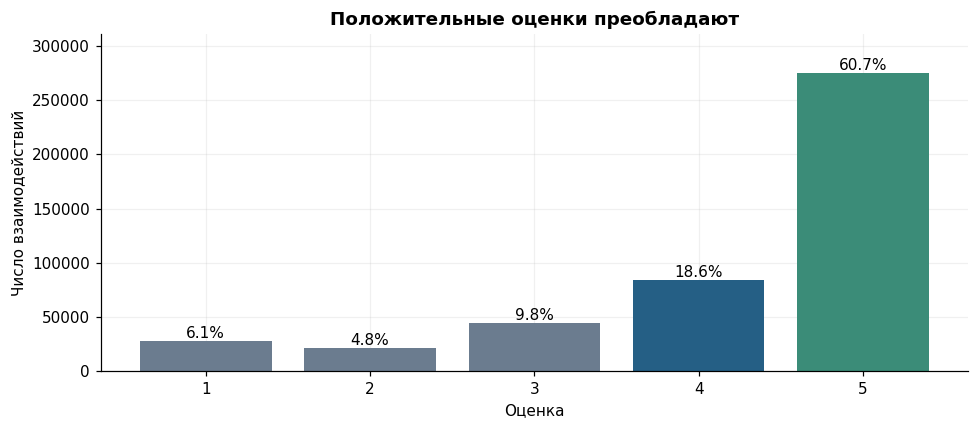

**Вывод:** оценки 4–5 составляют **79.3%**, а пятёрки — **60.7%**. Поэтому распределение классов несбалансировано. Основная задача — ранжирование новых товаров, а не точность угадывания наиболее частой оценки.

In [5]:
rating_counts = interactions.rating.value_counts().reindex(range(1, 6), fill_value=0)
positive_share = float((interactions.rating >= RELEVANCE_THRESHOLD).mean())
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values,
              color=[COLORS[4]]*3 + [COLORS[0], COLORS[2]])
for bar, count in zip(bars, rating_counts):
    ax.text(bar.get_x()+bar.get_width()/2, count, f'{count/len(interactions):.1%}',
            ha='center', va='bottom', fontsize=10)
ax.set(xlabel='Оценка', ylabel='Число взаимодействий',
       title='Положительные оценки преобладают', ylim=(0, rating_counts.max()*1.13))
show_figure('01_rating_distribution', fig)
display(Markdown(f'**Вывод:** оценки 4–5 составляют **{positive_share:.1%}**, '
    f'а пятёрки — **{rating_counts.loc[5]/len(interactions):.1%}**. '
    'Поэтому распределение классов несбалансировано. Основная задача — ранжирование '
    'новых товаров, а не точность угадывания наиболее частой оценки.'))

### 4. Активность и популярность

Количество событий показано в логарифмическом масштабе. Минимум пять взаимодействий обусловлен 5-core.


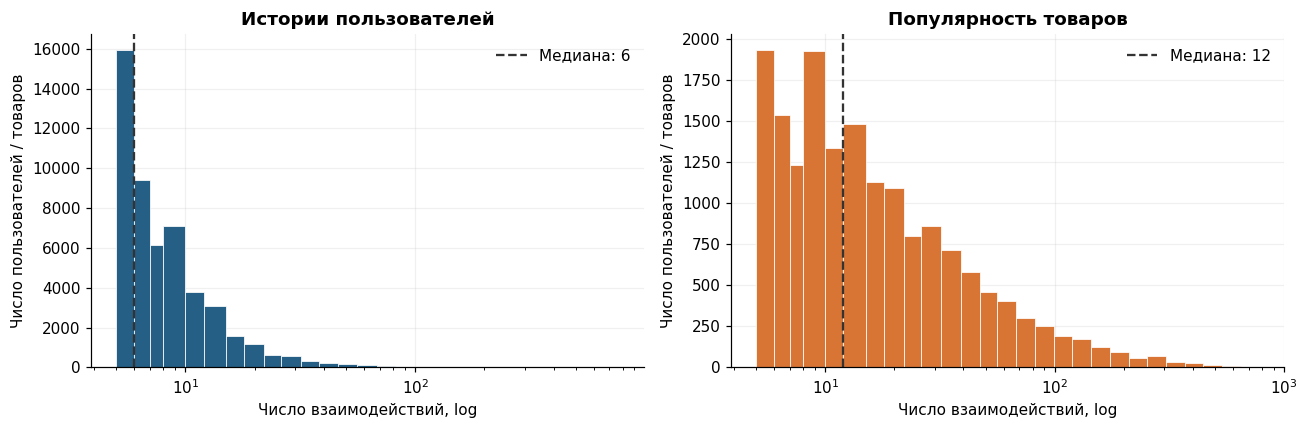

,Пользователи,Товары
count,"50,546.000","16,859.000"
mean,8.962,26.869
std,10.375,46.099
min,5.000,5.000
50%,6.000,12.000
90%,14.000,57.000
95%,20.000,95.000
99%,42.000,247.420
max,771.000,777.000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, series, title, color in zip(axes,
        [user_activity, item_popularity], ['Истории пользователей', 'Популярность товаров'], COLORS):
    bins = np.unique(np.geomspace(5, series.max()+1, 28).astype(int))
    ax.hist(series, bins=bins, color=color, edgecolor='white', linewidth=.5)
    ax.set_xscale('log')
    ax.set(xlabel='Число взаимодействий, log', ylabel='Число пользователей / товаров', title=title)
    ax.axvline(series.median(), color='#333333', linestyle='--', label=f'Медиана: {series.median():g}')
    ax.legend(frameon=False)
show_figure('02_activity_and_popularity', fig)
display(pd.DataFrame({'Пользователи': user_activity.describe(percentiles=[.5,.9,.95,.99]),
                      'Товары': item_popularity.describe(percentiles=[.5,.9,.95,.99])}))

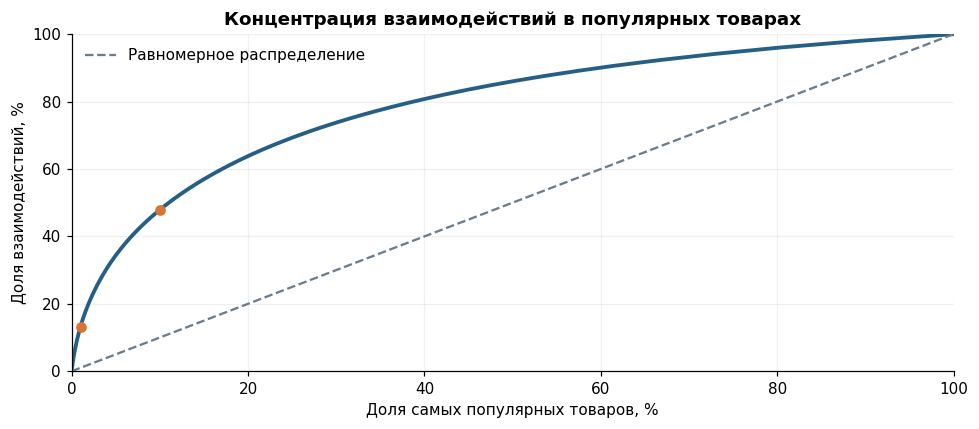

**Вывод:** верхний 1% товаров собирает **13.3%** взаимодействий, верхние 10% — **47.9%**. Это обосновывает дополнительный анализ качества по популярности товаров и catalog coverage; популярность сама по себе ещё не доказывает качество персональных рекомендаций.

In [7]:
pop_sorted = item_popularity.sort_values(ascending=False)
cumulative = pop_sorted.cumsum() / pop_sorted.sum()
top_one_count = math.ceil(len(pop_sorted)*.01)
top_ten_count = math.ceil(len(pop_sorted)*.10)
top_one_share = float(cumulative.iloc[top_one_count-1])
top_ten_share = float(cumulative.iloc[top_ten_count-1])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(cumulative)+1)/len(cumulative)*100, cumulative.values*100, linewidth=2.5)
ax.plot([0,100], [0,100], '--', color=COLORS[4], label='Равномерное распределение')
ax.scatter([100*top_one_count/n_items, 100*top_ten_count/n_items],
           [top_one_share*100, top_ten_share*100], color=COLORS[1], zorder=3)
ax.set(xlabel='Доля самых популярных товаров, %', ylabel='Доля взаимодействий, %',
       title='Концентрация взаимодействий в популярных товарах', xlim=(0,100), ylim=(0,100))
ax.legend(frameon=False)
show_figure('03_popularity_concentration', fig)
display(Markdown(f'**Вывод:** верхний 1% товаров собирает **{top_one_share:.1%}** взаимодействий, '
    f'верхние 10% — **{top_ten_share:.1%}**. Это обосновывает дополнительный анализ '
    'качества по популярности товаров и catalog coverage; популярность сама по себе ещё '
    'не доказывает качество персональных рекомендаций.'))

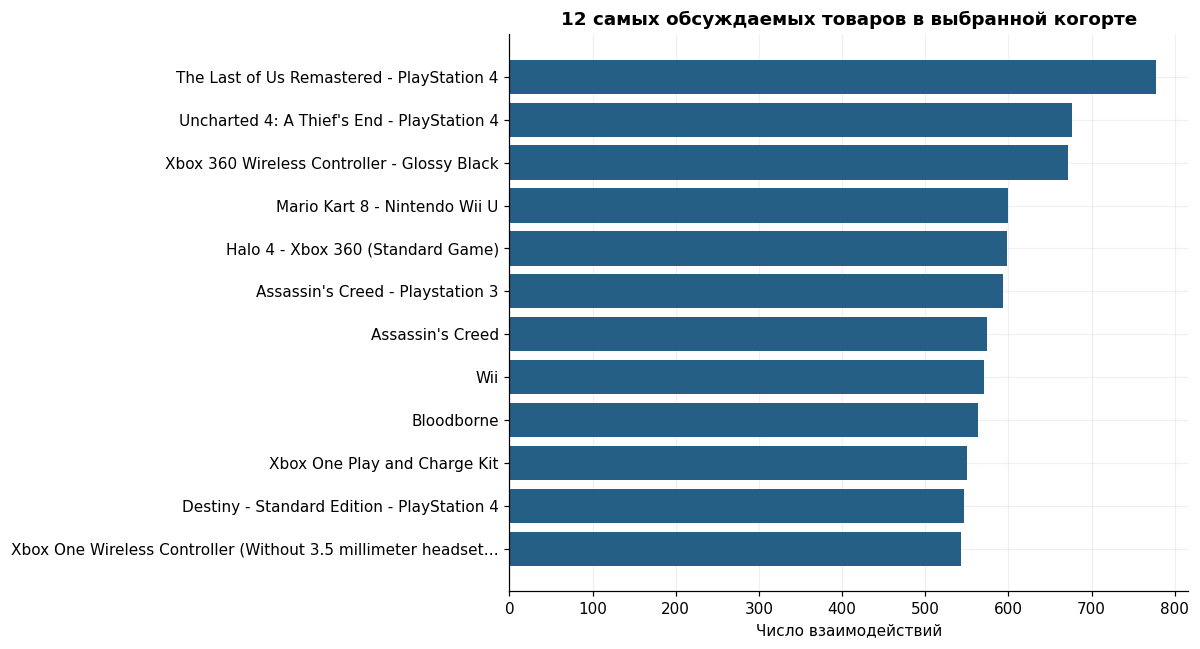

In [8]:
top_items = pop_sorted.head(12).rename('reviews').reset_index().merge(
    items[['item_id','title']], on='item_id', validate='one_to_one')
fig, ax = plt.subplots(figsize=(11, 6))
labels = [textwrap.shorten(t, width=65, placeholder='…') for t in top_items.title]
ax.barh(labels[::-1], top_items.reviews.iloc[::-1], color=COLORS[0])
ax.set(xlabel='Число взаимодействий', title='12 самых обсуждаемых товаров в выбранной когорте')
show_figure('04_top_items', fig)

### 5. Временная структура

2018 год представлен до 2 октября. Снижение числа отзывов может зависеть от отбора данных; это не оценка динамики рынка.


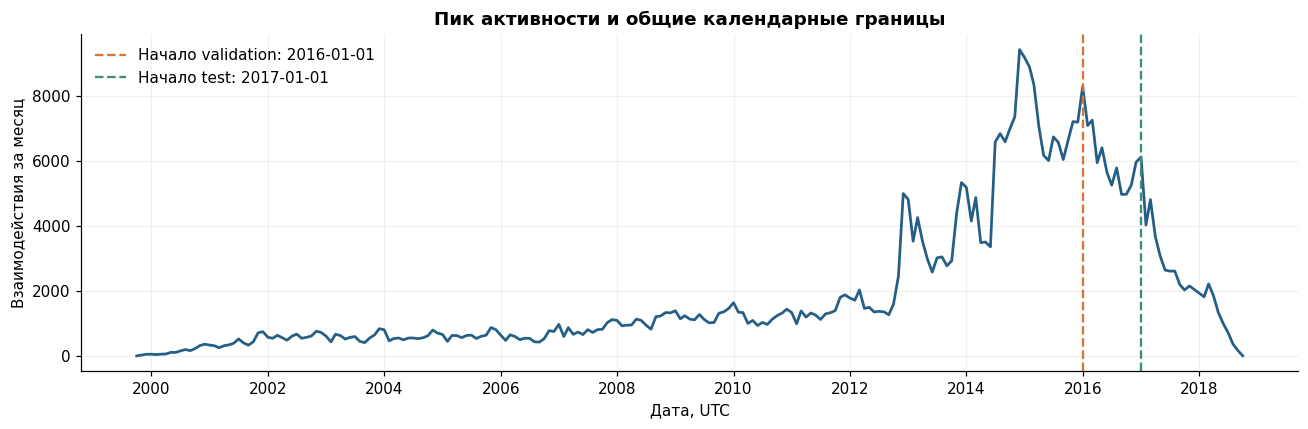

,Взаимодействия,Пользователи,Товары
datetime,,,
2011,16262,6455,4888
2012,22855,8333,6155
2013,43116,13753,8646
2014,68242,18838,10806
2015,85905,21997,12108
2016,72730,19776,11291
2017,37929,12347,8750
2018,11379,4777,4703


In [9]:
monthly = interactions.set_index('datetime').resample('MS').size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, color=COLORS[0], linewidth=1.8)
ax.axvline(VALIDATION_START, color=COLORS[1], linestyle='--', label='Начало validation: 2016-01-01')
ax.axvline(TEST_START, color=COLORS[2], linestyle='--', label='Начало test: 2017-01-01')
ax.set(xlabel='Дата, UTC', ylabel='Взаимодействия за месяц', title='Пик активности и общие календарные границы')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(frameon=False)
show_figure('05_monthly_activity', fig)
annual = interactions.groupby(interactions.datetime.dt.year).agg(
    interactions=('rating','size'), users=('user_id','nunique'), items=('item_id','nunique'))
display(annual.tail(8).rename(columns={'interactions':'Взаимодействия','users':'Пользователи','items':'Товары'}))

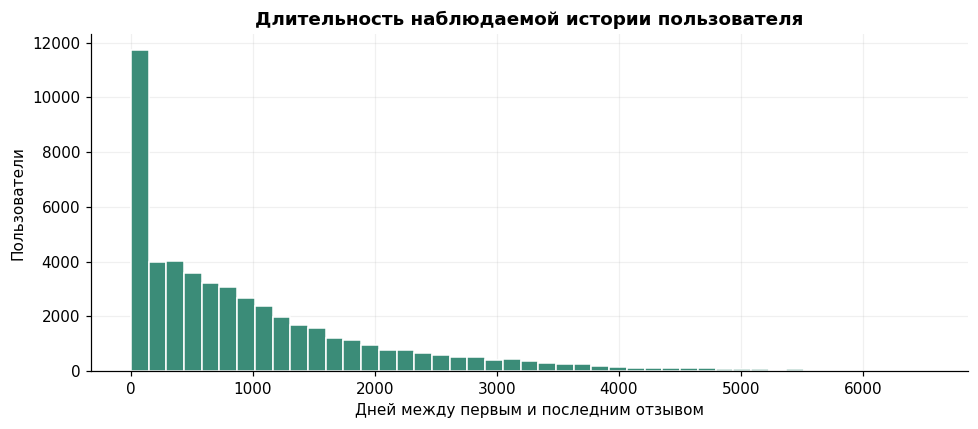

**Вывод:** 100.0% timestamp приходятся на 00:00 UTC: в этой выгрузке фактическая точность — день. Границы разбиения ставим между днями, не делим один день случайно. У **11.8%** пользователей все записи относятся к одному дню; это совместимо с пакетным написанием отзывов и не доказывает одновременные покупки.

In [10]:
user_dates = interactions.groupby('user_id').datetime.agg(['min','max','nunique'])
spans = (user_dates['max']-user_dates['min']).dt.days
midnight_share = float((interactions.timestamp % 86400 == 0).mean())
same_day_share = float((spans==0).mean())
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(spans, bins=45, color=COLORS[2], edgecolor='white')
ax.set(xlabel='Дней между первым и последним отзывом', ylabel='Пользователи',
       title='Длительность наблюдаемой истории пользователя')
show_figure('06_user_history_duration', fig)
display(Markdown(f'**Вывод:** {midnight_share:.1%} timestamp приходятся на 00:00 UTC: '
    'в этой выгрузке фактическая точность — день. Границы разбиения ставим между днями, '
    f'не делим один день случайно. У **{same_day_share:.1%}** пользователей все записи относятся '
    'к одному дню; это совместимо с пакетным написанием отзывов и не доказывает одновременные покупки.'))

### 6. Метаданные

Покрытие рассчитано по товарам и с весом по числу взаимодействий. Пустые строки и списки считаются пропусками.


,"Товары, %","Взаимодействия, %",Товаров без значения
Название,100.000,100.000,0.000
Бренд,99.324,99.713,114.000
Категории,99.128,99.568,147.000
Описание,96.785,97.675,542.000
Характеристики,87.662,91.801,"2,080.000"


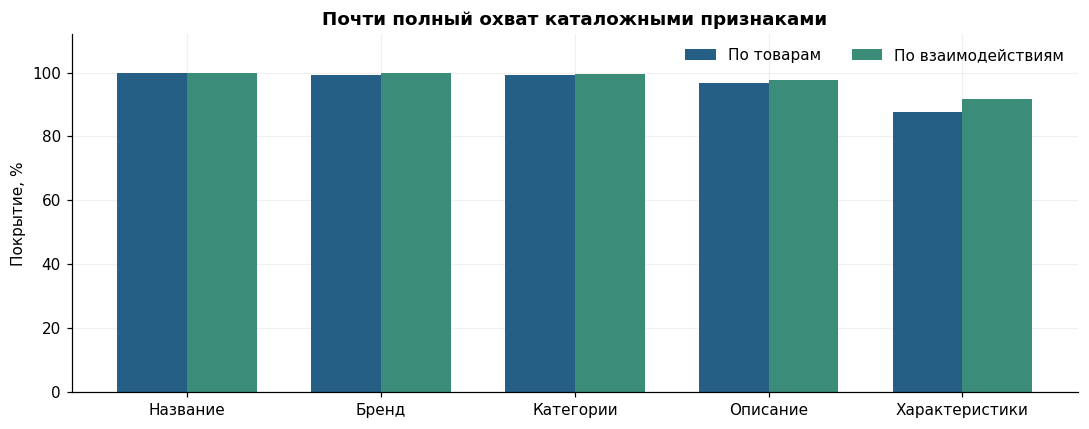

In [11]:
fields = ['title','brand','categories','description','features']
field_labels = ['Название','Бренд','Категории','Описание','Характеристики']
coverage = pd.DataFrame(index=fields)
for field in fields:
    present = items[field].map(bool)
    coverage.loc[field,'Товары, %'] = present.mean()*100
    weighted = items.item_id.map(item_popularity).fillna(0)
    coverage.loc[field,'Взаимодействия, %'] = weighted[present].sum()/len(interactions)*100
    coverage.loc[field,'Товаров без значения'] = (~present).sum()
coverage.index = field_labels
display(coverage)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(fields)); width=.36
ax.bar(x-width/2, coverage['Товары, %'], width, label='По товарам', color=COLORS[0])
ax.bar(x+width/2, coverage['Взаимодействия, %'], width, label='По взаимодействиям', color=COLORS[2])
ax.set_xticks(x, field_labels)
ax.set(ylabel='Покрытие, %', ylim=(0,112), title='Почти полный охват каталожными признаками')
ax.legend(frameon=False, ncols=2)
show_figure('07_metadata_coverage', fig)

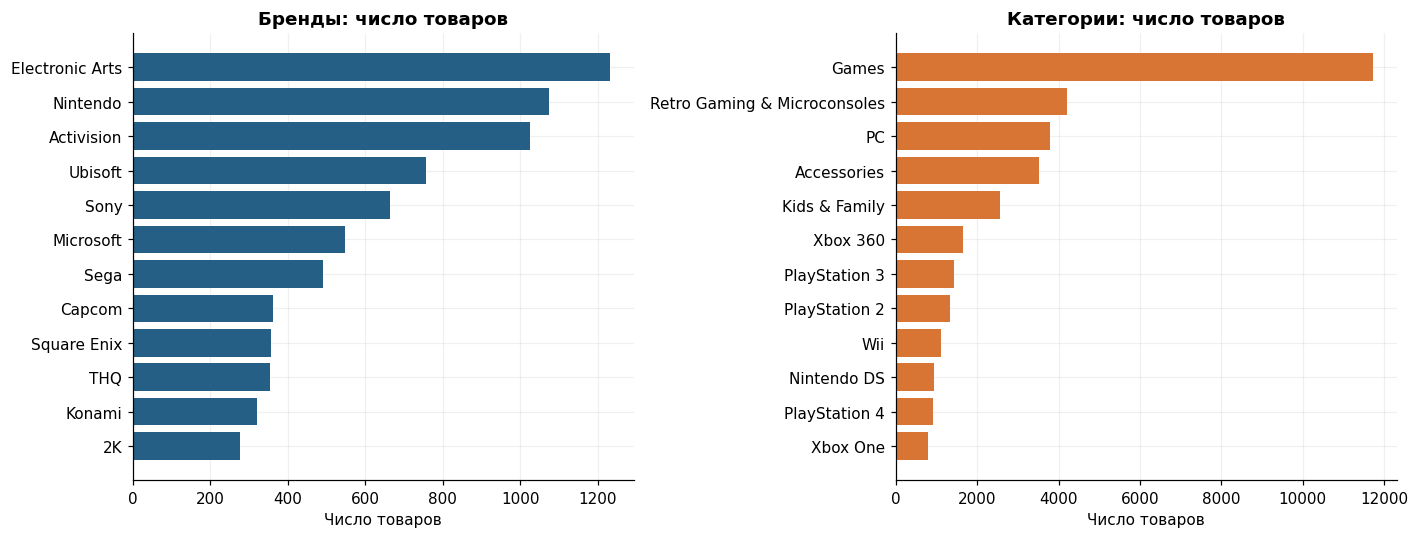

**Вывод:** найдено **1573** непустых значений бренда и **123** значений категорий с учётом корневой Video Games. Категории содержат платформы и типы товаров — это осмысленные признаки совместимости и интересов. Уровни иерархии пересекаются: столбцы категорий нельзя интерпретировать как непересекающиеся классы. Эти snapshot-поля исследуются только в EDA; в исправленной FM они не используются.

In [12]:
brand_counts = items.loc[items.brand.map(bool),'brand'].value_counts()
category_counts = items[['item_id','categories']].explode('categories').dropna().query(
    "categories != 'Video Games'").categories.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, values, title, color in zip(axes, [brand_counts.head(12), category_counts.head(12)],
        ['Бренды: число товаров', 'Категории: число товаров'], COLORS):
    labels=[textwrap.shorten(str(s), width=29, placeholder='…') for s in values.index]
    ax.barh(labels[::-1], values.iloc[::-1], color=color)
    ax.set(xlabel='Число товаров', title=title)
show_figure('08_brands_and_categories', fig)
display(Markdown(f'**Вывод:** найдено **{len(brand_counts)}** непустых значений бренда и '
    f'**{len(category_counts)+1}** значений категорий с учётом корневой Video Games. '
    'Категории содержат платформы и типы товаров — это осмысленные признаки совместимости и интересов. '
    'Уровни иерархии пересекаются: столбцы категорий нельзя интерпретировать как непересекающиеся классы. '
    'Эти snapshot-поля исследуются только в EDA; в исправленной FM они не используются.'))

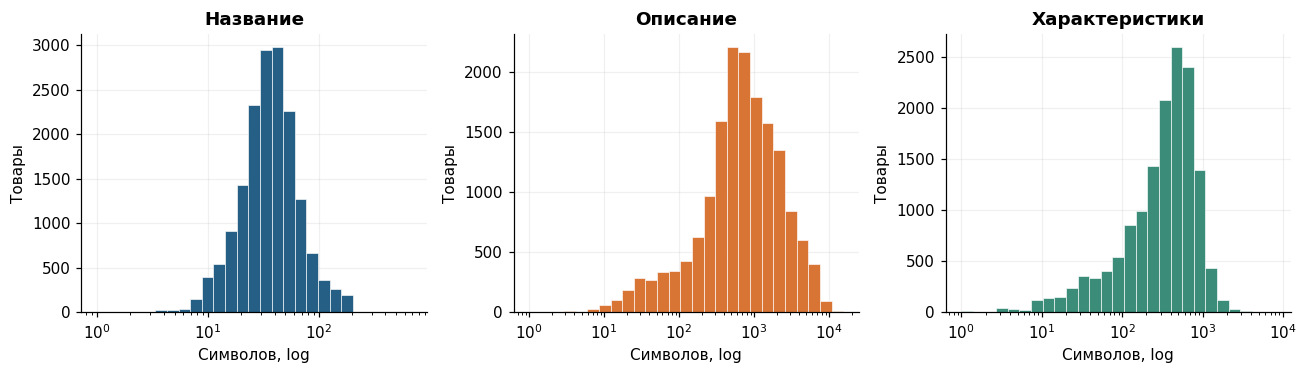

,Название,Описание,Характеристики
count,"16,859.000","16,859.000","16,859.000"
mean,43.100,"1,168.400",381.000
std,29.900,"1,437.300",363.200
min,3.000,0.000,0.000
50%,36.000,660.000,321.000
90%,73.200,"2,862.400",823.200
99%,164.000,"6,843.900","1,519.400"
max,679.000,"15,438.000","7,988.000"


**Вывод:** у **967** товаров нормализованное название совпадает с названием другого ASIN. Это повод для проверки вариантов издания, но не основание автоматически склеивать объекты: платформа, комплект и версия могут различаться. Длины текстов неоднородны. Истории редактирования карточек и отзывов нет, поэтому их текст и бренд/категории исключены из признаков исправленной FM.

In [13]:
text_lengths = pd.DataFrame({
    'Название': items.title.str.len(),
    'Описание': items.description.map(lambda x: len(' '.join(x))),
    'Характеристики': items.features.map(lambda x: len(' '.join(x))),
})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (field, values), color in zip(axes, text_lengths.items(), COLORS):
    nonempty=values[values>0]
    bins=np.geomspace(1, nonempty.max()+1, 28)
    ax.hist(nonempty, bins=bins, color=color, edgecolor='white', linewidth=.4)
    ax.set_xscale('log')
    ax.set(xlabel='Символов, log', ylabel='Товары', title=field)
show_figure('09_text_lengths', fig)
normalized_titles=items.title.str.casefold().str.replace(r'\W+', ' ', regex=True).str.strip()
title_groups=normalized_titles.value_counts()
duplicate_title_items=int(normalized_titles.isin(title_groups[title_groups>1].index).sum())
display(text_lengths.describe(percentiles=[.5,.9,.99]).round(1))
display(Markdown(f'**Вывод:** у **{fmt(duplicate_title_items)}** товаров нормализованное название '
    'совпадает с названием другого ASIN. Это повод для проверки вариантов издания, но не основание '
    'автоматически склеивать объекты: платформа, комплект и версия могут различаться. '
    'Длины текстов неоднородны. Истории редактирования карточек и отзывов нет, '
    'поэтому их текст и бренд/категории исключены из признаков исправленной FM.'))

**Признаки и доступность информации — версия temporal_metadata_v2**

| Признак | Правило |
|---|---|
| User/item ID | Словарь только по fit |
| Год и месяц первого fit-отзыва о товаре | One-hot; словарь и порог редкости только по fit-каталогу |
| Число fit-событий о товаре | log1p(n) / log1p(1000); все оценки учитываются одинаково |
| Возраст наблюдаемой истории товара | log1p((query − min timestamp)/86400) / log1p(3650) |
| Давность последнего fit-отзыва | log1p((query − max timestamp)/86400) / log1p(3650) |
| Бренд, категории, названия, описания, текст отзывов | Только EDA; в признаках моделей не используются |
| Будущие события, helpful votes, цена, sales rank, related items | Не используются |

«Возраст» — длительность наблюдаемой истории товара. Все timestamps предшествуют запросу; значения рейтингов в метапризнаки не входят.
Признаки фиксируются на начало holdout и используются для обучения и рекомендации.


### 7. Временное разбиение

Единые границы UTC для всех пользователей:

- Train: до 2016-01-01.
- Validation: 2016 год.
- Test: с 2017-01-01 до конца выгрузки.

Доли событий — примерно 73% / 16% / 11%. Границы зафиксированы до подбора моделей.
Глобальная ось исключает обучение на будущих событиях других пользователей
([Ji et al.](https://arxiv.org/abs/2010.11060)).
Подбор использует train → validation; финальное обучение — train + validation → test.
Окна validation и test имеют разную длительность.


In [14]:
train = interactions[interactions.datetime < VALIDATION_START].copy()
validation = interactions[(interactions.datetime >= VALIDATION_START) &
                           (interactions.datetime < TEST_START)].copy()
test = interactions[interactions.datetime >= TEST_START].copy()
final_fit = pd.concat([train, validation], ignore_index=True)
partitions={'train':train, 'validation':validation, 'test':test}
assert len(train)+len(validation)+len(test) == len(interactions)
assert train.datetime.max() < validation.datetime.min()
assert validation.datetime.max() < test.datetime.min()
assert final_fit.datetime.max() < test.datetime.min()
assert not train.index.intersection(validation.index).size
assert not train.index.intersection(test.index).size
assert not validation.index.intersection(test.index).size
split_rows=[]
for name, frame in partitions.items():
    split_rows.append({'Выборка':name, 'Взаимодействия':len(frame),
        'Доля, %':100*len(frame)/len(interactions), 'Пользователи':frame.user_id.nunique(),
        'Товары':frame.item_id.nunique(), 'Первая дата':frame.datetime.min().strftime('%Y-%m-%d'),
        'Последняя дата':frame.datetime.max().strftime('%Y-%m-%d')})
split_table=pd.DataFrame(split_rows).set_index('Выборка')
display(split_table)

,Взаимодействия,"Доля, %",Пользователи,Товары,Первая дата,Последняя дата
Выборка,,,,,,
train,330951,73.059,43463,15578,1999-10-14,2015-12-31
validation,72730,16.056,19776,11291,2016-01-01,2016-12-31
test,49308,10.885,14735,9766,2017-01-01,2018-10-02


### 8. Кандидаты и оценочная когорта

Для fit $F$ и будущего окна $W$:

- $I_F$ — все товары fit, включая оценки 1–3.
- $H_u(F)$ — все ранее оценённые товары пользователя; кандидаты $C_u=I_F\setminus H_u(F)$.
- $R_u(W)=\{i\in C_u:(u,i,r,t)\in W,\ r\ge4\}$ — доступные релевантные товары.
- В оценке участвуют известные пользователи с $|R_u|>0$ и минимум 10 кандидатами.

Пользователи, кандидаты и релевантность общие для всех моделей. Cold users/items исключены из warm-start оценки;
их количество и охват событий показаны отдельно. Дополнительного порога активности по holdout нет.
При недоступном персональном прогнозе применяется общий popularity fallback.
Рекомендации строятся на начало окна; история внутри окна не обновляется. Это batch top-N.


In [15]:
def evaluation_view(fit, holdout):
    fit_users=set(fit.user_id)
    catalog=frozenset(fit.item_id)
    histories=fit.groupby('user_id', observed=True).item_id.agg(frozenset).to_dict()
    warm_user=holdout.user_id.isin(fit_users)
    warm_item=holdout.item_id.isin(catalog)
    status=np.select([warm_user & warm_item, ~warm_user & warm_item,
                      warm_user & ~warm_item],
                     ['known_user_known_item','new_user_known_item','known_user_new_item'],
                     default='new_user_new_item')
    eligible=holdout[warm_user & warm_item]
    relevant=eligible[eligible.rating >= RELEVANCE_THRESHOLD]
    positives=relevant.groupby('user_id', observed=True).item_id.agg(frozenset).to_dict()
    history_counts=fit.groupby('user_id', observed=True).size()
    positive_history_counts=fit[fit.rating >= RELEVANCE_THRESHOLD].groupby('user_id', observed=True).size()
    query_rows=[]
    for user in sorted(positives):
        assert positives[user].isdisjoint(histories[user])
        assert positives[user].issubset(catalog)
        n_candidates=len(catalog)-len(histories[user])
        assert n_candidates >= K
        query_rows.append({'user_id':user, 'history':int(history_counts[user]),
            'positive_history':int(positive_history_counts.get(user,0)),
            'relevant':len(positives[user]), 'candidates':n_candidates})
    queries=pd.DataFrame(query_rows)
    stats={
        'fit_interactions':len(fit), 'fit_users':len(fit_users), 'catalog_items':len(catalog),
        'holdout_interactions':len(holdout), 'holdout_users':holdout.user_id.nunique(),
        'eligible_interactions':len(eligible), 'eligible_users':eligible.user_id.nunique(),
        'relevant_interactions':len(relevant), 'evaluation_users':len(queries),
        'known_users_without_available_relevance':holdout.loc[warm_user, 'user_id'].nunique()-len(queries),
        'all_positive_interactions':int((holdout.rating >= RELEVANCE_THRESHOLD).sum()),
        'positive_interaction_coverage':len(relevant)/int((holdout.rating >= RELEVANCE_THRESHOLD).sum()),
        'users_without_positive_fit_history':int((queries.positive_history==0).sum()),
        'minimum_candidate_count':int(queries.candidates.min()),
        'relevance_size_median':float(queries.relevant.median()),
        'cold_status_counts':pd.Series(status).value_counts().astype(int).to_dict(),
    }
    return {'stats':stats, 'catalog':catalog, 'histories':histories,
            'relevance':positives, 'queries':queries}

validation_view=evaluation_view(train, validation)
test_view=evaluation_view(final_fit, test)
views={'validation':validation_view, 'test':test_view}
cohort_table=pd.DataFrame({name:view['stats'] for name,view in views.items()}).drop('cold_status_counts')
display(cohort_table.rename(index={
    'fit_interactions':'Взаимодействия в fit','fit_users':'Пользователи в fit',
    'catalog_items':'Товары-кандидаты до персональной маски',
    'holdout_interactions':'Все взаимодействия будущего окна','holdout_users':'Все пользователи окна',
    'eligible_interactions':'События с известными пользователем и товаром',
    'eligible_users':'Известные пользователи с доступными событиями',
    'relevant_interactions':'Доступные релевантные взаимодействия',
    'evaluation_users':'Пользователи основной оценки',
    'known_users_without_available_relevance':'Известные пользователи без доступной релевантности',
    'all_positive_interactions':'Все положительные взаимодействия окна',
    'positive_interaction_coverage':'Доля доступных положительных событий',
    'users_without_positive_fit_history':'Оценочные пользователи без положительной истории fit',
    'minimum_candidate_count':'Минимальное число кандидатов у оценочного пользователя',
    'relevance_size_median':'Медианное число релевантных товаров'}))

,validation,test
Взаимодействия в fit,330951,403681
Пользователи в fit,43463,48349
Товары-кандидаты до персональной маски,15578,16721
Все взаимодействия будущего окна,72730,49308
Все пользователи окна,19776,14735
События с известными пользователем и товаром,31860,29488
Известные пользователи с доступными событиями,11905,11339
Доступные релевантные взаимодействия,25646,23454
Пользователи основной оценки,10207,9521
Известные пользователи без доступной релевантности,4683,3017


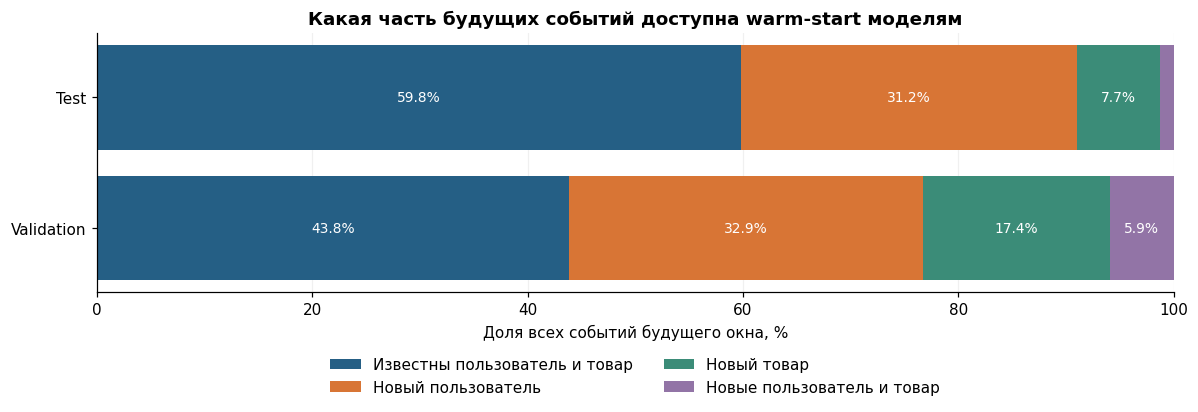

**Вывод:** основная оценка использует **10 207** пользователей validation и **9 521** пользователей test. После ограничения на известный каталог и пользователей доступно **42.9%** / **58.0%** положительных событий окон. Поэтому будущие метрики характеризуют warm-start часть когорты, а не весь сервис.

In [16]:
status_order=['known_user_known_item','new_user_known_item','known_user_new_item','new_user_new_item']
status_labels=['Известны пользователь и товар','Новый пользователь','Новый товар','Новые пользователь и товар']
status_frame=pd.DataFrame({name:view['stats']['cold_status_counts'] for name,view in views.items()}).reindex(status_order).fillna(0)
fig, ax=plt.subplots(figsize=(11,4))
left=np.zeros(2)
for status,label,color in zip(status_order,status_labels,COLORS):
    values=status_frame.loc[status].to_numpy()/status_frame.sum().to_numpy()*100
    ax.barh(['Validation','Test'], values, left=left, label=label, color=color)
    for j,value in enumerate(values):
        if value>5: ax.text(left[j]+value/2,j,f'{value:.1f}%',ha='center',va='center',color='white',fontsize=9)
    left+=values
ax.set(xlabel='Доля всех событий будущего окна, %', xlim=(0,100), title='Какая часть будущих событий доступна warm-start моделям')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(.5,-.2), ncols=2)
show_figure('10_cold_start_breakdown',fig)
display(Markdown(f'**Вывод:** основная оценка использует '
    f'**{fmt(validation_view["stats"]["evaluation_users"])}** пользователей validation и '
    f'**{fmt(test_view["stats"]["evaluation_users"])}** пользователей test. '
    f'После ограничения на известный каталог и пользователей доступно '
    f'**{validation_view["stats"]["positive_interaction_coverage"]:.1%}** / '
    f'**{test_view["stats"]["positive_interaction_coverage"]:.1%}** положительных событий окон. '
    'Поэтому будущие метрики характеризуют warm-start часть когорты, а не весь сервис.'))

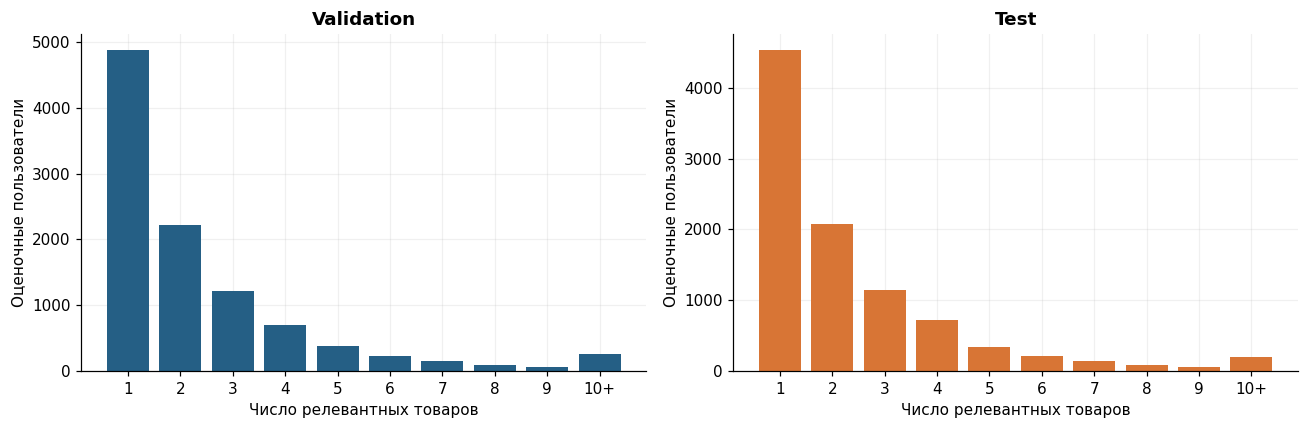

,validation,test
"История до границы, событий",,
1–4,5943,4561
5–9,2766,3149
10+,1498,1811


In [17]:
fig, axes=plt.subplots(1,2,figsize=(12,4))
for ax,(name,view),color in zip(axes,views.items(),COLORS):
    counts=view['queries'].relevant.clip(upper=10).value_counts().reindex(range(1,11),fill_value=0)
    ax.bar(range(1,11),counts.values,color=color)
    ax.set_xticks(range(1,11),[str(i) for i in range(1,10)]+['10+'])
    ax.set(xlabel='Число релевантных товаров',ylabel='Оценочные пользователи',title=name.capitalize())
show_figure('11_relevance_per_query',fig)
activity_slices={}
for name,view in views.items():
    bins=pd.cut(view['queries'].history,bins=[0,4,9,np.inf],labels=['1–4','5–9','10+'])
    activity_slices[name]=bins.value_counts(sort=False).to_dict()
display(pd.DataFrame(activity_slices).rename_axis('История до границы, событий'))

### 9. Метрики и правила общего сравнения

**Основная метрика до подбора — NDCG@10. Дополнительная — Recall@10.**
Обе метрики считаем на бинарной релевантности `rating >= 4` для всех моделей, независимо от их
обучающего таргета. Для пользователя $u$ пусть $L_u=(i_1,\ldots,i_{10})$, $y_j=\mathbb{1}[i_j\in R_u]$.

$$\mathrm{Recall@10}_u = \frac{|L_u\cap R_u|}{|R_u|}$$
$$\mathrm{NDCG@10}_u = \frac{\sum_{j=1}^{10} y_j/\log_2(j+1)}
{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}$$

Макроусреднение по пользователям. Ранжируется весь каталог кандидатов без sampling; top-10 содержит разные товары.
Ties разрешаются по ASIN. При недоступном прогнозе или NaN/inf у кандидата вся выдача пользователя заменяется популярностью положительных fit-событий.

Настройки выбираются только по validation NDCG@10. Дополнительно считаются coverage, fallback, срезы истории 1–4/5–9/10+ и head/tail.
Head — верхние 10% fit-товаров по числу положительных отзывов; tail — остальные.
Парный bootstrap: 2 000 повторов, seed=42, 95%. Интервалы условны на обученных моделях, без поправки за множественные сравнения.


### 10. Разбиение и сохранение протокола

`data/splits/` содержит все события каждого периода, включая cold start. Train + validation объединяются при финальном обучении.
В Git сохранены протокол и агрегаты; данные и веса исключены.


In [18]:
split_dir=ROOT/'data/splits'
split_dir.mkdir(parents=True,exist_ok=True)
split_manifest={}
for name,frame in partitions.items():
    path=split_dir/f'{name}.csv.gz'
    with deterministic_gzip(path) as stream:
        frame[['user_id','item_id','rating','timestamp']].to_csv(stream,index=False,lineterminator='\n')
    split_manifest[name]={
        'path':str(path.relative_to(ROOT)), 'sha256':sha256(path),
        'interactions':len(frame), 'users':frame.user_id.nunique(), 'items':frame.item_id.nunique(),
        'start_utc':frame.datetime.min().isoformat(), 'end_utc':frame.datetime.max().isoformat()}

protocol={
    'version':1, 'status':'fixed_before_model_training', 'seed':SEED, 'k':K,
    'relevance':{'rating_at_least':RELEVANCE_THRESHOLD,'binary':True},
    'validation_start_utc':VALIDATION_START.isoformat(), 'test_start_utc':TEST_START.isoformat(),
    'validation_fit':'train', 'test_fit':'train + validation, after hyperparameter selection',
    'query_time':'start of each holdout window; frozen history throughout the window',
    'catalog':'all items observed in the stage fit, regardless of rating',
    'candidates':'entire fit catalog minus all items seen by that user in fit; no sampling',
    'evaluation_users':'known in stage fit, >=1 available relevant holdout item, >=10 candidates',
    'cold_start':'excluded from primary metrics; counts and coverage reported; retained in split files',
    'users_without_relevance':'excluded from macro Recall/NDCG; counts reported',
    'missing_personal_scores':'if personalization is unavailable or any candidate score is non-finite, replace the entire user ranking by descending count of rating>=4 fit events; ties by item_id; never drop users',
    'ties':'descending finite score, then ascending lexicographic item_id',
    'primary_metric':'macro NDCG@10', 'secondary_metric':'macro Recall@10',
    'diagnostics':['catalog coverage@10','fit-history slices 1-4 / 5-9 / 10+','fit-popularity slices'],
    'confidence_intervals':{'method':'paired user bootstrap','resamples':2000,'confidence':.95,'seed':SEED},
    'feature_preprocessing':'fit only; rebuild on train+validation for final test',
    'limitations':['source and restored 5-core use full-period cohort selection',
                  'catalog metadata are crawl-time snapshots; historical availability unverified',
                  'review timestamp is day-resolution feedback, not purchase time',
                  'unequal validation/test horizons and temporal drift',
                  'warm-start observed-rating retrieval, not causal online recommendation quality'],
    'input_checksums':audit['outputs'], 'splits':split_manifest,
    'evaluation_diagnostics':{name:view['stats'] for name,view in views.items()},
}
preserve_or_create_report(ROOT/'reports/evaluation_protocol.json', protocol)
eda_summary={
    'interactions':len(interactions),'users':n_users,'items':n_items,'density':density,
    'positive_rating_fraction':positive_share,'top_one_percent_item_interaction_share':top_one_share,
    'top_ten_percent_item_interaction_share':top_ten_share,'same_day_history_user_fraction':same_day_share,
    'timestamp_midnight_fraction':midnight_share,'duplicate_normalized_title_items':duplicate_title_items,
    'metadata_coverage':coverage.to_dict(orient='index'),'unique_nonempty_brands':len(brand_counts),
    'unique_categories_including_root':len(category_counts)+1,
    'user_history_slices':activity_slices,'library_versions':versions,
}
preserve_or_create_report(ROOT/'reports/eda_summary.json', eda_summary)
for name,frame in partitions.items():
    restored=pd.read_csv(split_dir/f'{name}.csv.gz',dtype={'user_id':'string','item_id':'string',
        'rating':'int8','timestamp':'int64'})
    pd.testing.assert_frame_equal(frame[['user_id','item_id','rating','timestamp']].reset_index(drop=True),restored)
print('Разбиение хронологично; файлы перечитаны без изменений; параметры и контрольные суммы сохранены.')

Разбиение хронологично; файлы перечитаны без изменений; параметры и контрольные суммы сохранены.


### 11. Выводы по EDA

In [19]:
display(Markdown(f'''
1. **Размер подходит:** {fmt(len(interactions))} событий, {fmt(n_users)} пользователей, {fmt(n_items)} товаров;
   разреженность {(1-density):.3%}, медиана истории {user_activity.median():g} событий.
2. **Положительный перекос:** {positive_share:.1%} оценок — 4–5; relevance и top-10 метрики зафиксированы.
3. **Концентрация популярности:** верхние 10% товаров дают {top_ten_share:.1%} событий;
   поэтому рядом с общими метриками нужны head/tail и coverage.
4. **Метаданные:** карточки исследованы в EDA, но их исторические версии неизвестны.
   В исправленной FM используются только датированные временные и поведенческие атрибуты товара.
   Их эффект проверяется ablation при одинаковых настройках, а не предполагается заранее.
5. **Глобальное время:** train до 2016, validation — 2016, test — с 2017;
   query на границе окна, история заморожена, после выбора настроек — refit train+validation.
6. **Ограничения:** warm-start покрывает {test_view['stats']['positive_interaction_coverage']:.1%}
   положительных test-событий; полный 5-core, исходный отбор по snapshot-названию и длинный test-горизонт
   ограничивают переносимость. Карточки не используются в предиктивных признаках v2.

Семинары ветки 26f проверены: наш Amazon Video Games не используется.
Далее приведены пять validation-сравнений и корректирующая финальная оценка v2.
Test уже оценивался в предыдущей версии; эта история использования явно сохранена.
'''))



1. **Размер подходит:** 452 989 событий, 50 546 пользователей, 16 859 товаров;
   разреженность 99.947%, медиана истории 6 событий.
2. **Положительный перекос:** 79.3% оценок — 4–5; relevance и top-10 метрики зафиксированы.
3. **Концентрация популярности:** верхние 10% товаров дают 47.9% событий;
   поэтому рядом с общими метриками нужны head/tail и coverage.
4. **Метаданные:** карточки исследованы в EDA, но их исторические версии неизвестны.
   В исправленной FM используются только датированные временные и поведенческие атрибуты товара.
   Их эффект проверяется ablation при одинаковых настройках, а не предполагается заранее.
5. **Глобальное время:** train до 2016, validation — 2016, test — с 2017;
   query на границе окна, история заморожена, после выбора настроек — refit train+validation.
6. **Ограничения:** warm-start покрывает 58.0%
   положительных test-событий; полный 5-core, исходный отбор по snapshot-названию и длинный test-горизонт
   ограничивают переносимость. Карточки не используются в предиктивных признаках v2.

Семинары ветки 26f проверены: наш Amazon Video Games не используется.
Далее приведены пять validation-сравнений и корректирующая финальная оценка v2.
Test уже оценивался в предыдущей версии; эта история использования явно сохранена.


### 12. ItemKNN

`models/item_knn.py`: бинарный cosine с overlap shrinkage ([Sarwar et al.](https://files.grouplens.org/papers/www10_sarwar.pdf)).

Пусть $B_{ui}=1$ только для **fit-оценки 4–5**, иначе 0. Все оценки 1–3 остаются в истории и
каталоге, но не создают положительную связь между товарами. Обозначим
$c_{ij}=\sum_u B_{ui}B_{uj}$ и $n_i=\sum_u B_{ui}$. Тогда:

$$s_{ij}=\begin{cases}
\dfrac{c_{ij}}{\sqrt{n_i n_j}}\dfrac{c_{ij}}{c_{ij}+\lambda}, & i\ne j,\ c_{ij}>0,\\
0,&\text{иначе.}
\end{cases}$$

При $\lambda=0$ получаем обычное cosine similarity. При $\lambda>0$ совпадение на одном-двух
пользователях получает меньший вес. Для каждого **целевого** товара $i$ сохраняем $m$ соседей
с максимальным $s_{ij}$, равные веса разрешаем по ASIN. После усечения граф не обязан быть симметричным.

$$\widehat r_{ui}=\sum_{j\in N_m(i)} B_{uj}s_{ij}.$$

Матрица хранит целевые товары по строкам; пакетный прогноз $BS^T$.
При нулевых scores всех кандидатов применяется общий fallback. Частично нулевой хвост ранжируется по ASIN.


### 13. Общий оценщик

`FitData` строит ID-словари по fit; `EvaluationContext` фиксирует когорту, релевантность, каталог и историю.
Модели передают `score_batch(user_ids, query_timestamp=...)` без holdout-меток.
Оценщик проверяет соответствие fit/каталога, маскирует известные товары, применяет fallback и считает метрики.
Top-10 проверен полным сортированием, включая ties на границе.

Тесты формул, градиентов, временных границ, масок, ties, fallback и метрик:
```sh
python -m unittest discover -s tests -v
```


In [20]:
from models.item_knn import ItemKNN
from evaluation import EvaluationContext, evaluate_model

search_configuration=json.loads((ROOT/'configs/item_knn_search.json').read_text())
display(pd.Series({
    'Метод':search_configuration['model'],
    'Число соседей':str(search_configuration['grid']['n_neighbors']),
    'Shrinkage':str(search_configuration['grid']['shrinkage']),
    'Бюджет':search_configuration['budget'],
    'Критерий выбора':search_configuration['selection'],
    'Равенство основной метрики':search_configuration['tie_break'],
},name='Зафиксировано до запуска').to_frame())


,Зафиксировано до запуска
Метод,ItemKNN
Число соседей,"[20, 50, 100, 200]"
Shrinkage,"[0.0, 10.0, 50.0]"
Бюджет,12
Критерий выбора,maximum validation macro NDCG@10
Равенство основной метрики,"fewer neighbors, then smaller shrinkage; no se..."


### 14. Подбор ItemKNN

$m\in\{20,50,100,200\}$, $\lambda\in\{0,10,50\}$: 12 конфигураций.
Выбор по validation NDCG@10; ties: меньше соседей, затем меньше shrinkage.
План сохранён до обучения. Используются только train и validation, вся когорта и полный каталог.
Контроль — популярность положительных fit-отзывов с теми же масками и метриками.


In [21]:
validation_runs=load_validation_report(ROOT,'item_knn')
assert validation_runs['summary']['cohort']['evaluation_users']==validation_view['stats']['evaluation_users']
assert validation_runs['summary']['cohort']['relevant_interactions']==validation_view['stats']['relevant_interactions']
assert validation_runs['summary']['completed_trials']==12
assert validation_runs['summary']['test_evaluated'] is False
search_results=validation_runs['search'].sort_values(
    ['ndcg_at_10','n_neighbors','shrinkage'],ascending=[False,True,True]).reset_index(drop=True)
columns=['n_neighbors','shrinkage','ndcg_at_10','recall_at_10','catalog_coverage_at_10',
         'fallback_rate','fit_seconds','evaluation_seconds']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(search_results[columns])

,n_neighbors,shrinkage,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,fit_seconds,evaluation_seconds
0,100,10.000000,0.021111,0.032179,0.738798,0.051435,0.337878,1.277437
1,200,10.000000,0.021053,0.031936,0.734369,0.051435,0.411082,1.439080
2,50,10.000000,0.021031,0.032057,0.746566,0.051435,0.286753,1.079337
3,200,50.000000,0.020942,0.032029,0.711516,0.051435,0.411943,1.432614
4,100,50.000000,0.020885,0.031872,0.715753,0.051435,0.447174,1.278256
5,50,50.000000,0.020839,0.031999,0.725510,0.051435,0.284098,1.091421
6,20,10.000000,0.020710,0.031267,0.765695,0.051533,0.250426,1.007829
7,20,50.000000,0.020543,0.031112,0.748042,0.051533,0.246629,1.016145
8,200,0.000000,0.015092,0.022641,0.854988,0.051435,0.404334,1.423342
9,20,0.000000,0.015070,0.022635,0.857235,0.051533,0.264489,0.999462


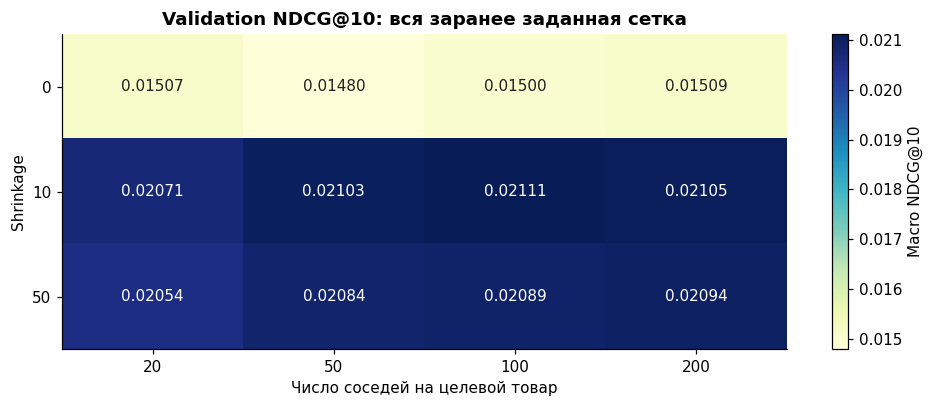

In [22]:
heat=validation_runs['search'].pivot(index='shrinkage',columns='n_neighbors',values='ndcg_at_10').sort_index()
fig,ax=plt.subplots(figsize=(9,3.8))
image=ax.imshow(heat.values,cmap='YlGnBu',aspect='auto')
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),[f'{x:g}' for x in heat.index])
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        value=heat.iloc[row,col]
        text_color='white' if value>(heat.values.min()+heat.values.max())/2 else '#202020'
        ax.text(col,row,f'{value:.5f}',ha='center',va='center',color=text_color)
ax.grid(False)
ax.set(xlabel='Число соседей на целевой товар',ylabel='Shrinkage',title='Validation NDCG@10: вся заранее заданная сетка')
fig.colorbar(image,ax=ax,label='Macro NDCG@10')
show_figure('12_item_knn_validation_grid',fig)

### 15. Результат первой модели и контроль популярности

Далее представлены **validation-результаты**. Лучшая конфигурация уже выбиралась на этих же
пользователях, поэтому её преимущество и интервалы не являются независимой финальной проверкой.
Времена зависят от машины и нагрузки; это фактические замеры отдельных запусков, а не метрика подбора.
Общее чтение файлов и построение общей индексации не включены в fit_seconds отдельных конфигураций.

,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
model,,,,,,,
Popularity (control),0.005779,0.010252,0.000963,0.000000,10207,1.224501,0.000000
ItemKNN (selected),0.021111,0.032179,0.738798,0.051435,10207,1.277437,0.337878


estimate   ci_low  ci_high
metric       estimate_for                            
ndcg_at_10   ItemKNN       0.021111 0.019287 0.023026
             Popularity    0.005779 0.004977 0.006649
             difference    0.015333 0.013472 0.017275
recall_at_10 ItemKNN       0.032179 0.029379 0.035092
             Popularity    0.010252 0.008781 0.011881
             difference    0.021928 0.018886 0.025032

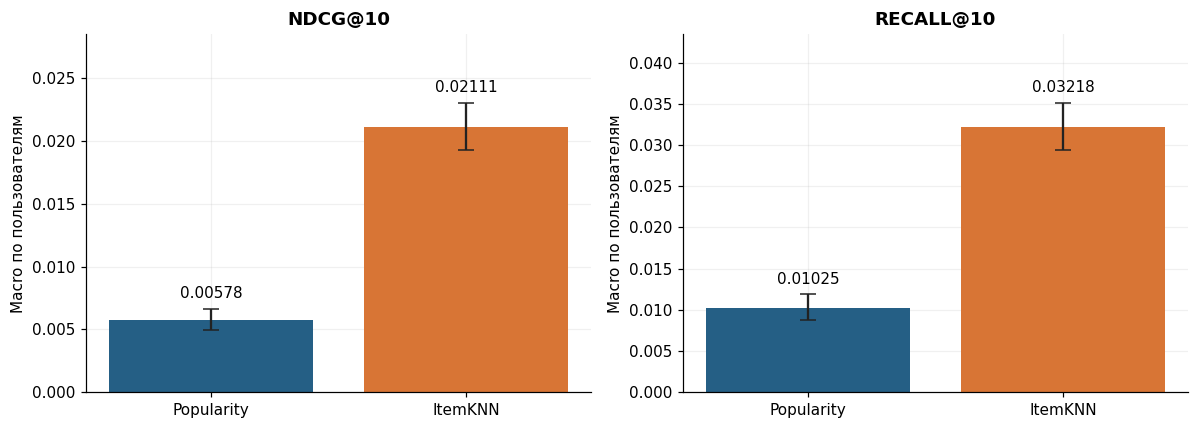

In [23]:
comparison=validation_runs['comparison']
intervals=validation_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(comparison.set_index('model'))
    display(intervals.set_index(['metric','estimate_for']))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    values=comparison[metric].to_numpy()
    ax.bar(['Popularity','ItemKNN'],values,color=COLORS[:2])
    for position,(label,value) in enumerate(zip(['Popularity','ItemKNN'],values)):
        row=intervals[(intervals.metric==metric)&(intervals.estimate_for==label)].iloc[0]
        errors=np.maximum(0,np.array([[value-row.ci_low],[row.ci_high-value]]))
        ax.errorbar(position,value,yerr=errors,fmt='none',color='#222222',capsize=5)
        ax.text(position,row.ci_high+max(values)*.04,f'{value:.5f}',ha='center')
    ax.set(title=metric.replace('_at_','@').upper(),ylabel='Macro по пользователям',ylim=(0,max(values)*1.35))
show_figure('13_item_knn_vs_popularity',fig)

### 16. Диагностика: история, популярность и fallback

Срезы истории определяются **только по train**. Head — верхние 10% fit-каталога по числу
положительных fit-отзывов (ties по ASIN); tail — остальные 90%. В таблице head/tail Recall
пересчитывается по соответствующей части релевантных объектов, но рекомендации остаются прежними.
Пользователь может участвовать в обоих срезах, поэтому их метрики не усредняются в общий Recall.

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238

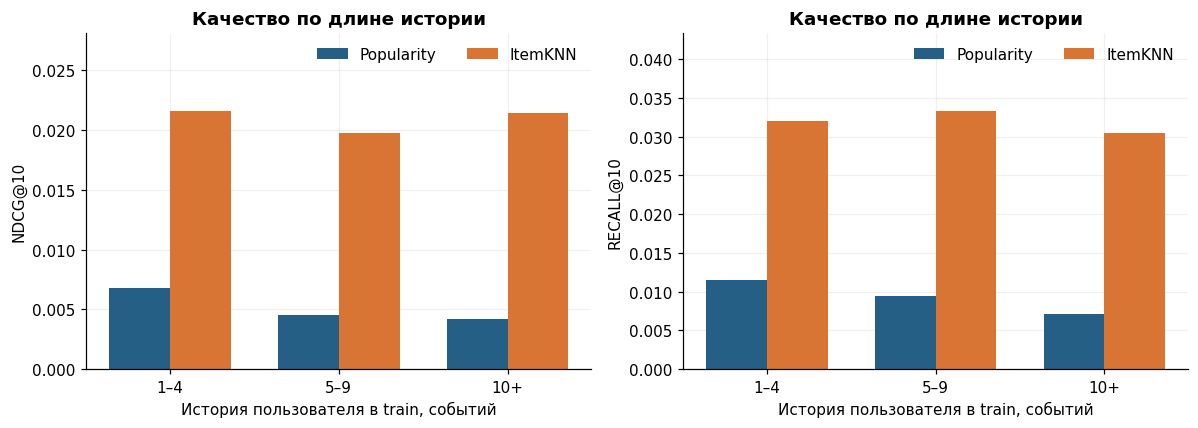

In [24]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(validation_runs['history_slices'])
    display(validation_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(11,4))
x=np.arange(3);width=.36
for ax,metric in zip(axes,['ndcg','recall']):
    for offset,(model,color) in enumerate(zip(['Popularity','ItemKNN'],COLORS)):
        values=validation_runs['history_slices'].loc[model][metric].to_numpy()
        ax.bar(x+(offset-.5)*width,values,width,label=model,color=color)
    ax.set_xticks(x,['1–4','5–9','10+'])
    ax.set(xlabel='История пользователя в train, событий',ylabel=metric.upper()+'@10',title='Качество по длине истории')
    ax.set_ylim(0,validation_runs['history_slices'][metric].max()*1.3)
    ax.legend(frameon=False,ncols=2)
show_figure('14_item_knn_history_slices',fig)

### 17. Выводы по первой модели

In [25]:
best_parameters=validation_runs['summary']['best_params']
best_metrics=validation_runs['summary']['best_validation_metrics']
control_metrics=validation_runs['summary']['popularity_validation_metrics']
relative_ndcg=best_metrics['ndcg_at_10']/control_metrics['ndcg_at_10']-1 if control_metrics['ndcg_at_10'] else float('nan')
unshrunk_ndcg=float(validation_runs['search'].loc[
    (validation_runs['search'].n_neighbors==best_parameters['n_neighbors']) &
    (validation_runs['search'].shrinkage==0),'ndcg_at_10'].iloc[0])
ndcg_difference=intervals[(intervals.metric=='ndcg_at_10')&(intervals.estimate_for=='difference')].iloc[0]
recall_difference=intervals[(intervals.metric=='recall_at_10')&(intervals.estimate_for=='difference')].iloc[0]
display(Markdown(f"""
Выбраны **{best_parameters['n_neighbors']} соседей, shrinkage={best_parameters['shrinkage']:g}**.
Validation: **NDCG@10={best_metrics['ndcg_at_10']:.6f}, Recall@10={best_metrics['recall_at_10']:.6f}**.
Прирост NDCG относительно Popularity — **{relative_ndcg:.1%}**;
95% CI разности: **[{ndcg_difference.ci_low:.6f}; {ndcg_difference.ci_high:.6f}]**.
Без shrinkage при том же числе соседей NDCG={unshrunk_ndcg:.6f}.
"""))



Выбраны **100 соседей, shrinkage=10**.
Validation: **NDCG@10=0.021111, Recall@10=0.032179**.
Прирост NDCG относительно Popularity — **265.3%**;
95% CI разности: **[0.013472; 0.017275]**.
Без shrinkage при том же числе соседей NDCG=0.015001.


### 18. iALS

`models/ials.py`, [Hu, Koren, Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf).

Берём бинарное предпочтение $p_{ui}=1$ для fit-оценки 4–5, иначе 0, и
$c_{ui}=1+\alpha p_{ui}$. В частности, **ненаблюдаемые пары имеют confidence 1**, а не 0.
Оценки 1–3 не становятся положительными сигналами, но остаются в общей маске истории.

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^T y_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

При фиксированных $Y$ обновляем каждого пользователя точным решением системы:

$$\left(Y^TY+\alpha\sum_{i:p_{ui}=1}y_i y_i^T+\lambda I\right)x_u
=(1+\alpha)\sum_{i:p_{ui}=1}y_i.$$

Товары обновляются аналогично. Используется точное `numpy.linalg.solve`; регуляризация не зависит от степени.
Item-факторы инициализированы с seed=42. Пустой положительный профиль даёт нулевой вектор и общий fallback.


### 19. Подбор iALS

$f\in\{16,32,64\}$, $\alpha\in\{10,40\}$, $\lambda\in\{0.1,1\}$: 12 конфигураций.
Каждая обучена 15 итераций, seed=42. Выбор по validation NDCG@10; ties: меньше факторов, меньше alpha, больше lambda.
Точная train loss вычислена через Gram-матрицы; её невозрастание проверяет реализацию.
Сравнение использует выбранную CF (100 соседей, shrinkage=10), общую когорту и маски.


In [26]:
ials_configuration=json.loads((ROOT/'configs/ials_search.json').read_text())
display(pd.Series({
    'Число факторов':str(ials_configuration['grid']['n_factors']),
    'Alpha':str(ials_configuration['grid']['alpha']),
    'Lambda':str(ials_configuration['grid']['regularization']),
    'Итерации':ials_configuration['n_iterations'],
    'Seed':ials_configuration['seed'],
    'Конфигурации':ials_configuration['budget'],
    'Критерий':ials_configuration['selection'],
},name='Зафиксированный план iALS').to_frame())


,Зафиксированный план iALS
Число факторов,"[16, 32, 64]"
Alpha,"[10.0, 40.0]"
Lambda,"[0.1, 1.0]"
Итерации,15
Seed,42
Конфигурации,12
Критерий,maximum validation macro NDCG@10


In [27]:
ials_runs=load_validation_report(ROOT,'ials')
assert ials_runs['summary']['completed_trials']==12
assert ials_runs['summary']['test_evaluated'] is False
assert ials_runs['summary']['cohort_fingerprint']==json.loads((ROOT/'reports/item_knn_validation/summary.json').read_text())['cohort_fingerprint']
assert ials_runs['summary']['cohort']['evaluation_users']==10207
ials_search=ials_runs['search'].sort_values(
    ['ndcg_at_10','n_factors','alpha','regularization'],ascending=[False,True,True,False])
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_search[['n_factors','alpha','regularization','ndcg_at_10','recall_at_10',
        'catalog_coverage_at_10','fallback_rate','fit_seconds','evaluation_seconds','last_relative_loss_decrease']])

,n_factors,alpha,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,fit_seconds,evaluation_seconds,last_relative_loss_decrease
10,64,40.000000,0.100000,0.021893,0.034360,0.143215,0.050260,44.419219,1.582736,0.001003
11,64,40.000000,1.000000,0.021805,0.034215,0.143728,0.050260,43.294342,1.507528,0.001858
9,64,10.000000,1.000000,0.021663,0.034499,0.090320,0.050260,42.706728,1.517855,0.000588
8,64,10.000000,0.100000,0.021652,0.034341,0.090833,0.050260,43.688998,1.483316,0.000389
7,32,40.000000,1.000000,0.021022,0.032723,0.088330,0.050260,10.940124,1.563004,0.001169
6,32,40.000000,0.100000,0.020868,0.032795,0.087367,0.050260,10.789307,1.466264,0.000705
4,32,10.000000,0.100000,0.020407,0.032499,0.054693,0.050260,11.003952,1.495845,0.000250
5,32,10.000000,1.000000,0.020331,0.032371,0.054500,0.050260,10.767218,1.495836,0.000364
2,16,40.000000,0.100000,0.018547,0.030460,0.050135,0.050260,3.144182,1.447818,0.000386
3,16,40.000000,1.000000,0.018469,0.030347,0.050006,0.050260,3.115576,1.453825,0.000650


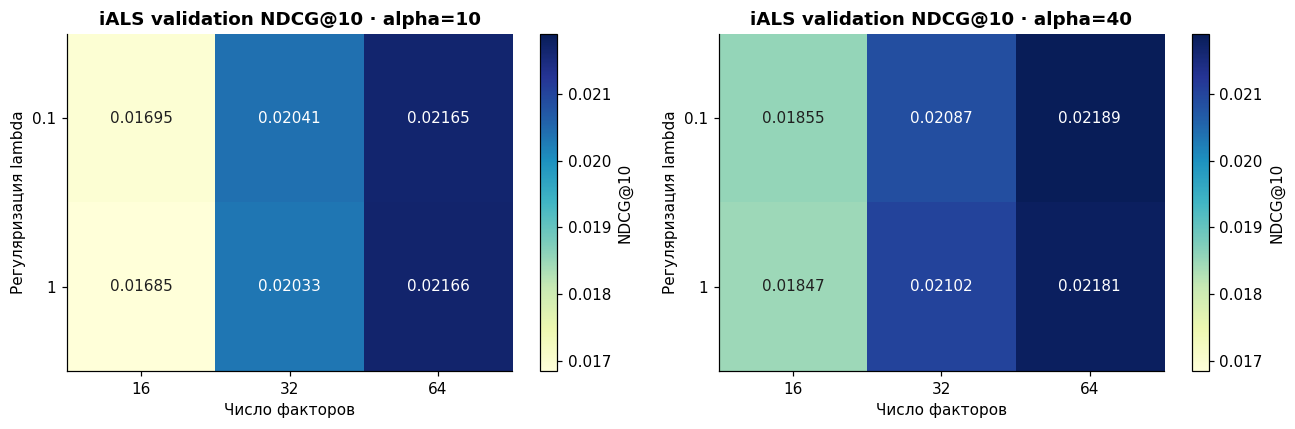

In [28]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
minimum=ials_search.ndcg_at_10.min();maximum=ials_search.ndcg_at_10.max()
for ax,alpha in zip(axes,[10.,40.]):
    table=ials_search[ials_search.alpha==alpha].pivot(index='regularization',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=minimum,vmax=maximum,aspect='auto')
    ax.set_xticks(range(len(table.columns)),table.columns)
    ax.set_yticks(range(len(table.index)),[f'{v:g}' for v in table.index])
    for row in range(table.shape[0]):
        for col in range(table.shape[1]):
            value=table.iloc[row,col]
            ax.text(col,row,f'{value:.5f}',ha='center',va='center',
                color='white' if value>(minimum+maximum)/2 else '#202020')
    ax.grid(False)
    ax.set(xlabel='Число факторов',ylabel='Регуляризация lambda',title=f'iALS validation NDCG@10 · alpha={alpha:g}')
    fig.colorbar(im,ax=ax,label='NDCG@10')
show_figure('15_ials_validation_grid',fig)

### 20. Оптимизация iALS

Кривые показывают train loss. Validation не используется для остановки.
Fit-время включает подсчёт loss; чтение и индексация исключены. Времена разных запусков — ориентир, а не строгий аппаратный benchmark.


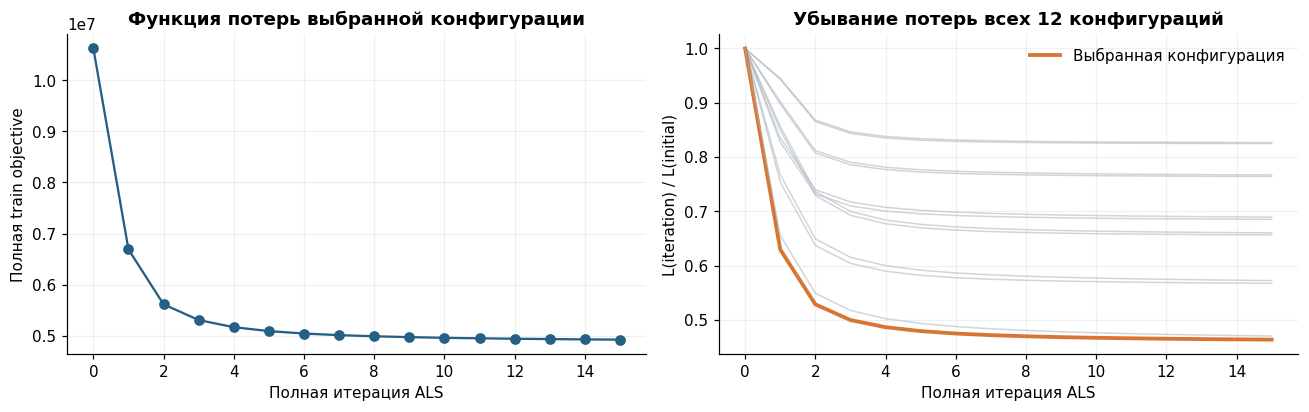

Относительное снижение потерь на последней итерации: 0.1003%


In [29]:
ials_curve=ials_runs['curve']
ials_best_params=ials_runs['summary']['best_params']
ials_winner=ials_search.iloc[0]
ials_best_trial=int(ials_winner.trial)
best_curve=ials_curve[ials_curve.trial==ials_best_trial].sort_values('iteration')
for trial,curve in ials_curve.groupby('trial'):
    values=curve.sort_values('iteration').objective.to_numpy()
    assert len(values)==16 and np.all(np.diff(values)<=1e-7*max(1,values[0]))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(best_curve.iteration,best_curve.objective,marker='o',color=COLORS[0])
axes[0].set(xlabel='Полная итерация ALS',ylabel='Полная train objective',title='Функция потерь выбранной конфигурации')
for trial,curve in ials_curve.groupby('trial'):
    curve=curve.sort_values('iteration');chosen=trial==ials_best_trial
    axes[1].plot(curve.iteration,curve.objective/curve.objective.iloc[0],
        color=COLORS[1] if chosen else '#AAB4BD',linewidth=2.5 if chosen else 1,
        alpha=1 if chosen else .55,label='Выбранная конфигурация' if chosen else None)
axes[1].set(xlabel='Полная итерация ALS',ylabel='L(iteration) / L(initial)',title='Убывание потерь всех 12 конфигураций')
axes[1].legend(frameon=False)
show_figure('16_ials_training_objective',fig)
print('Относительное снижение потерь на последней итерации:',
      f'{ials_winner.last_relative_loss_decrease:.4%}')

### 21. iALS и ItemKNN на validation

Парный bootstrap использует общих пользователей. После HPO эти интервалы описательные: они не учитывают оптимизм выбора настроек.


,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
model,,,,,,,
Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219


estimate    ci_low  ci_high
metric       estimate_for                             
ndcg_at_10   iALS          0.021893  0.020066 0.023882
             ItemKNN       0.021111  0.019287 0.023026
             difference    0.000782 -0.001015 0.002595
recall_at_10 iALS          0.034360  0.031527 0.037376
             ItemKNN       0.032179  0.029379 0.035092
             difference    0.002181 -0.000720 0.005099

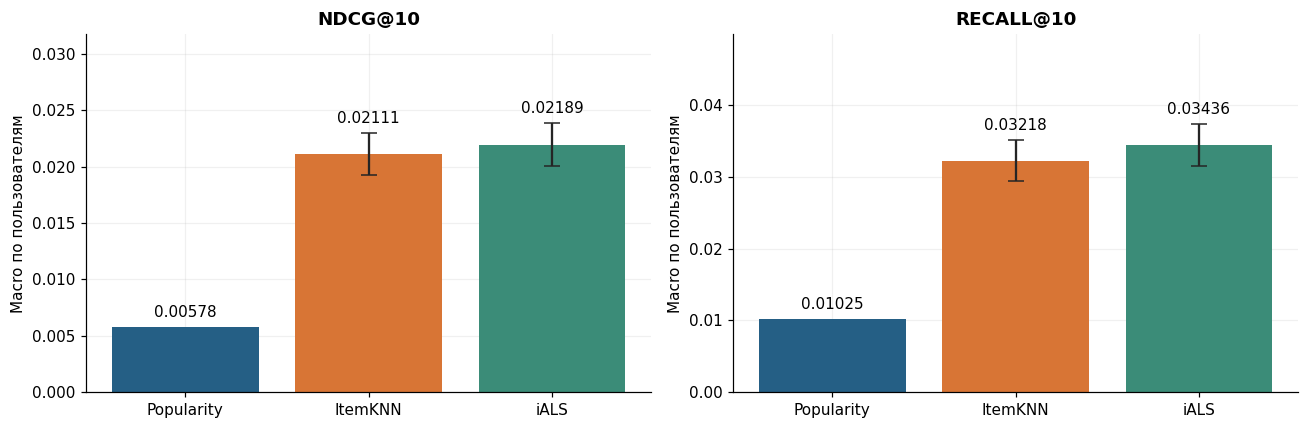

In [30]:
ials_comparison=ials_runs['comparison']
ials_intervals=ials_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_comparison.set_index('model'))
    display(ials_intervals.set_index(['metric','estimate_for']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['ndcg_at_10','recall_at_10']):
    values=ials_comparison[metric].to_numpy()
    ax.bar(ials_comparison.model,values,color=COLORS[:3])
    for position,(name,value) in enumerate(zip(ials_comparison.model,values)):
        ci=ials_intervals[(ials_intervals.metric==metric)&(ials_intervals.estimate_for==name)]
        upper=value
        if len(ci):
            ci=ci.iloc[0];upper=ci.ci_high
            errors=np.maximum(0,np.array([[value-ci.ci_low],[ci.ci_high-value]]))
            ax.errorbar(position,value,yerr=errors,fmt='none',color='#252525',capsize=5)
        ax.text(position,upper+max(values)*.04,f'{value:.5f}',ha='center')
    ax.set(title=metric.replace('_at_','@').upper(),ylabel='Macro по пользователям',ylim=(0,max(values)*1.45))
show_figure('17_ials_vs_item_knn',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851

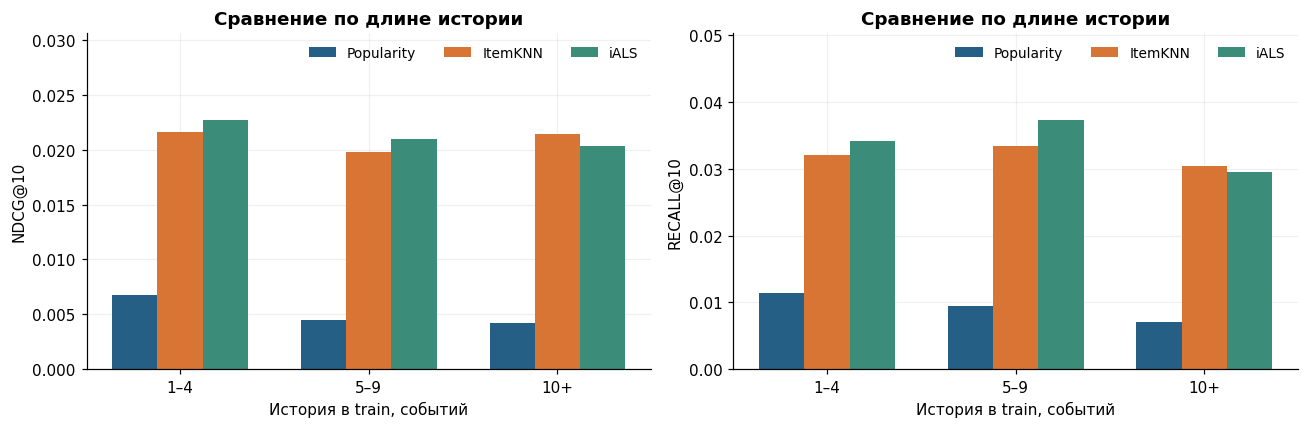

In [31]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ials_runs['history_slices'])
    display(ials_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(12,4));positions=np.arange(3);width=.24
for ax,metric in zip(axes,['ndcg','recall']):
    for offset,(name,color) in enumerate(zip(['Popularity','ItemKNN','iALS'],COLORS)):
        values=ials_runs['history_slices'].loc[name][metric].to_numpy()
        ax.bar(positions+(offset-1)*width,values,width,label=name,color=color)
    ax.set_xticks(positions,['1–4','5–9','10+'])
    ax.set(xlabel='История в train, событий',ylabel=metric.upper()+'@10',
        title='Сравнение по длине истории',ylim=(0,ials_runs['history_slices'][metric].max()*1.35))
    ax.legend(frameon=False,ncols=3,fontsize=9)
show_figure('18_ials_history_slices',fig)

### 22. Выводы по iALS

In [32]:
ials_metrics=ials_runs['summary']['best_validation_metrics']
cf_metrics=ials_runs['summary']['cf_validation_metrics']
ndcg_delta=ials_metrics['ndcg_at_10']-cf_metrics['ndcg_at_10']
recall_delta=ials_metrics['recall_at_10']-cf_metrics['recall_at_10']
difference=ials_intervals[(ials_intervals.metric=='ndcg_at_10')&(ials_intervals.estimate_for=='difference')].iloc[0]
verdict='выше, чем' if ndcg_delta>0 else 'ниже, чем' if ndcg_delta<0 else 'такой же, как'
ndcg_interval_text='не включает ноль' if difference.ci_low>0 or difference.ci_high<0 else 'включает ноль'
tail=ials_runs['popularity_slices']
head_ials=tail.loc[('iALS','head_top_10_percent'),'recall_at_10']
head_cf=tail.loc[('ItemKNN','head_top_10_percent'),'recall_at_10']
tail_ials=tail.loc[('iALS','tail_other_90_percent'),'recall_at_10']
tail_cf=tail.loc[('ItemKNN','tail_other_90_percent'),'recall_at_10']
display(Markdown(f"""
Validation: **NDCG@10={ials_metrics['ndcg_at_10']:.6f}, Recall@10={ials_metrics['recall_at_10']:.6f}**.
iALS − CF по NDCG: **{ndcg_delta:+.6f}**, 95% CI **[{difference.ci_low:.6f}; {difference.ci_high:.6f}]** ({ndcg_interval_text}).
Recall head: iALS={head_ials:.6f}, CF={head_cf:.6f}; tail: iALS={tail_ials:.6f}, CF={tail_cf:.6f}.
Выигрыш в общей метрике не означает улучшение всех срезов.
"""))



Validation: **NDCG@10=0.021893, Recall@10=0.034360**.
iALS − CF по NDCG: **+0.000782**, 95% CI **[-0.001015; 0.002595]** (включает ноль).
Recall head: iALS=0.081696, CF=0.056922; tail: iALS=0.002851, CF=0.014238.
Выигрыш в общей метрике не означает улучшение всех срезов.


### 23. Третья модель: EASE с нуля

По [Steck (2019), EASE](https://arxiv.org/abs/1905.03375) обучаем линейное восстановление
бинарной положительной истории $X$ ($rating\ge4$):
$$\min_B \|X-XB\|_F^2+\lambda\|B\|_F^2,\quad \mathrm{diag}(B)=0.$$
$$P=(X^\top X+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\;(i\ne j),\quad B_{jj}=0.$$
Столбец $j$ содержит веса исходных товаров для предсказания целевого товара $j$; $scores=XB$.

`models/ease.py`: точное разложение Холецкого и SPD-инверсия SciPy, float64.
Веса не усекаются; отрицательные коэффициенты сохраняются. Оценки 1–3 дают нулевой вход и остаются в маске истории.


### 24. Подбор EASE

$\lambda\in\{1,10,30,100,300,1000,10000\}$: семь конфигураций.
Выбор по validation NDCG@10; ties: большее $\lambda$. Инициализация детерминирована.
Каталог, когорта и маски общие с CF/iALS; нулевой прогноз всех кандидатов передаётся fallback.


In [33]:
ease_config=json.loads((ROOT/'configs/ease_search.json').read_text())
display(pd.Series(ease_config,name='Зафиксированный план EASE').to_frame())


,Зафиксированный план EASE
model,EASE
preference,X_ui=1 for fit rating >=4; otherwise 0
objective,"||X-XB||_F^2 + lambda*||B||_F^2, diag(B)=0; un..."
grid,"{'regularization': [1.0, 10.0, 30.0, 100.0, 30..."
budget,7
selection,maximum validation macro NDCG@10
tie_break,larger regularization
dtype,float64
approximation,"none; full dense signed matrix, no pruning or ..."
test_evaluated,False


In [34]:
ease_runs=load_validation_report(ROOT,'ease')
assert ease_runs['summary']['completed_trials']==7
assert ease_runs['summary']['test_evaluated'] is False
assert ease_runs['summary']['cohort']['evaluation_users']==10207
ease_search=ease_runs['search'].sort_values(['ndcg_at_10','regularization'],ascending=[False,False]).reset_index(drop=True)
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(ease_search)

,trial,regularization,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,catalog_items,weight_bytes,nonzero_weights,negative_weights,negative_fraction_of_nonzero,training_objective
0,4,100.000000,0.023372,0.035191,0.497689,0.051435,10207,1.705730,18.140118,15578,1941392672,237853506,110083966,0.462823,233191.091650
1,3,30.000000,0.023062,0.034908,0.543459,0.051435,10207,1.702111,18.837018,15578,1941392672,237853506,107121728,0.450369,213684.486866
2,5,300.000000,0.022912,0.034628,0.483053,0.051435,10207,1.719215,18.008492,15578,1941392672,237853506,117224714,0.492844,245498.519901
3,6,1000.000000,0.022120,0.033417,0.484337,0.051435,10207,1.929608,20.436331,15578,1941392672,237853506,128126828,0.538680,253289.466983
4,2,10.000000,0.021882,0.033175,0.627038,0.051435,10207,1.821197,18.845576,15578,1941392672,237853506,108675360,0.456900,192498.358573
5,7,10000.000000,0.021387,0.032597,0.489986,0.051435,10207,1.810961,21.505512,15578,1941392672,237853506,136419468,0.573544,258313.707809
6,1,1.000000,0.017876,0.026578,0.738927,0.051435,10207,1.770697,16.536922,15578,1941392672,237853506,115429176,0.485295,153506.762549


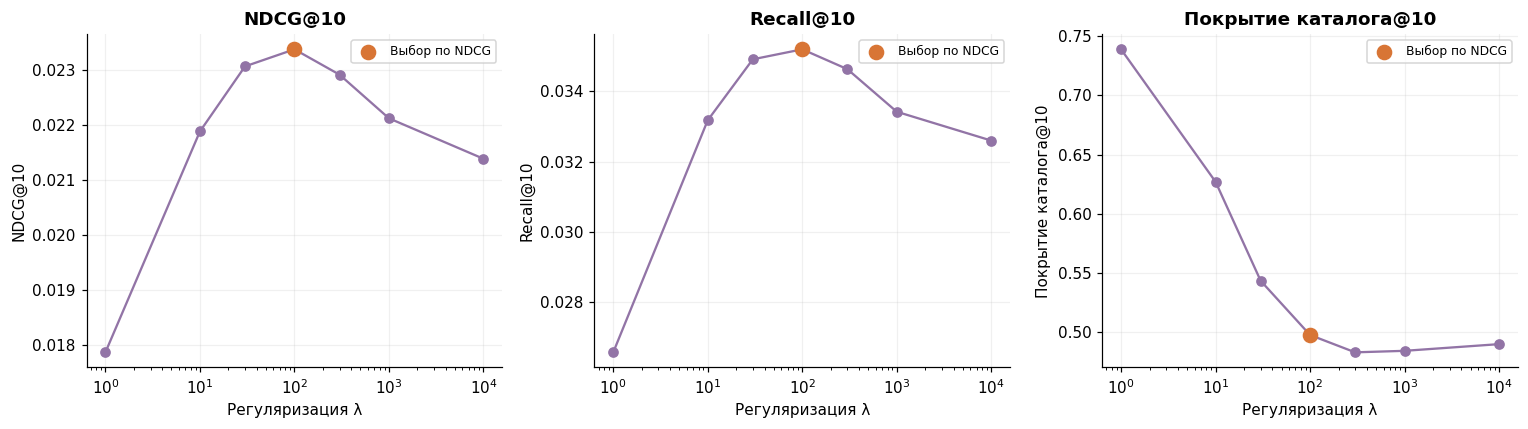

In [35]:
ease_grid=ease_search.sort_values('regularization')
ease_lambda=ease_runs['summary']['best_params']['regularization']
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10','catalog_coverage_at_10'],['NDCG@10','Recall@10','Покрытие каталога@10']):
    ax.plot(ease_grid.regularization,ease_grid[metric],marker='o',color=COLORS[3])
    best=ease_grid[ease_grid.regularization==ease_lambda].iloc[0]
    ax.scatter([ease_lambda],[best[metric]],s=85,color=COLORS[1],zorder=4,label='Выбор по NDCG')
    ax.set_xscale('log');ax.set_xlabel('Регуляризация λ');ax.set_ylabel(label)
    ax.set_title(label);ax.legend(fontsize=8)
show_figure('19_ease_regularization',fig)

### 25. Диагностика EASE

Память — $O(|I|^2)$, факторизация — $O(|I|^3)$.
Train objective в оптимуме: $\sum_j1/P_{jj}-\lambda|I|$.
Тесты проверяют её и веса через отдельные ridge-регрессии. Отрицательные веса допустимы; диагональ равна нулю.


In [36]:
ease_diagnostics=ease_runs['summary']['best_model_diagnostics']
display(pd.Series(ease_diagnostics,name='Диагностика выбранного EASE').to_frame())
print(f"Матрица весов: {ease_diagnostics['weight_bytes']/2**30:.3f} GiB; float64")

,Диагностика выбранного EASE
catalog_items,"15,578.000"
negative_fraction_of_nonzero,0.463
negative_weights,"110,083,966.000"
nonzero_weights,"237,853,506.000"
training_objective,"233,191.092"
weight_bytes,"1,941,392,672.000"


Матрица весов: 1.808 GiB; float64


### 26. EASE, ItemKNN и iALS на validation

CF/iALS используют выбранные настройки. Сравнение выполнено на общей когорте.
Bootstrap после HPO описательный; времена получены в отдельных запусках.


,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,EASE,0.023372,0.021480,0.025366
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,0.002260,0.001279,0.003287
3,ItemKNN,recall_at_10,EASE,0.035191,0.032197,0.038147
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,0.003012,0.001157,0.004870
6,iALS,ndcg_at_10,EASE,0.023372,0.021480,0.025366
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,0.001478,-0.000202,0.003204
9,iALS,recall_at_10,EASE,0.035191,0.032197,0.038147


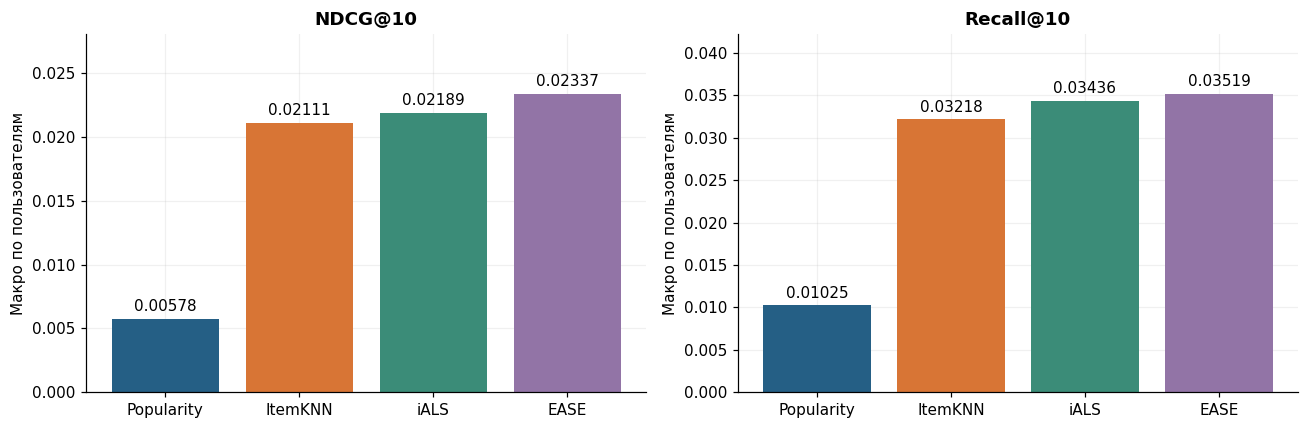

In [37]:
ease_comparison=ease_runs['comparison']
ease_intervals=ease_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ease_comparison)
    display(ease_intervals)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(ease_comparison.model,ease_comparison[metric],color=COLORS[:4])
    for i,value in enumerate(ease_comparison[metric]):
        ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,ease_comparison[metric].max()*1.2);ax.set_title(label)
    ax.set_ylabel('Макро по пользователям')
show_figure('20_ease_vs_cf_ials',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670

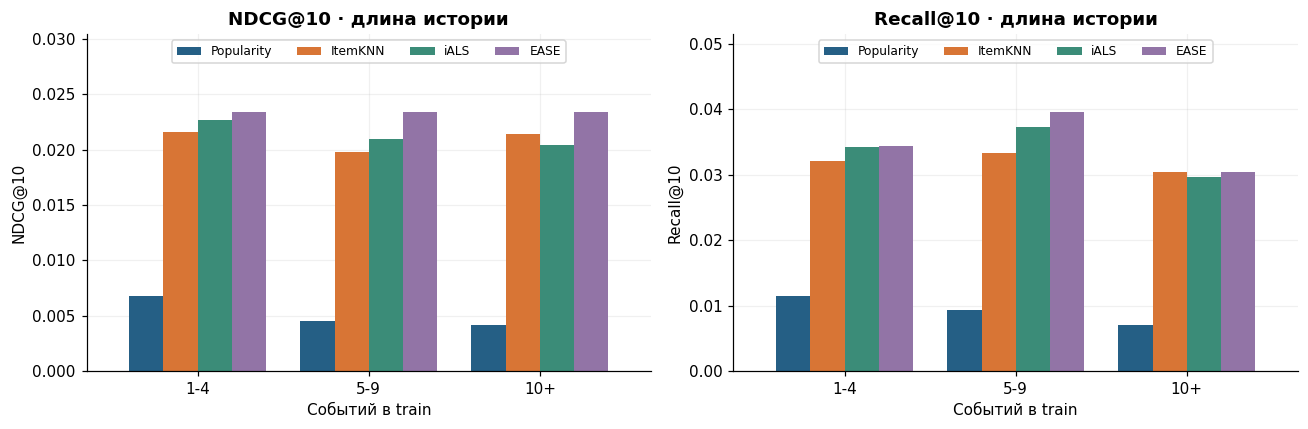

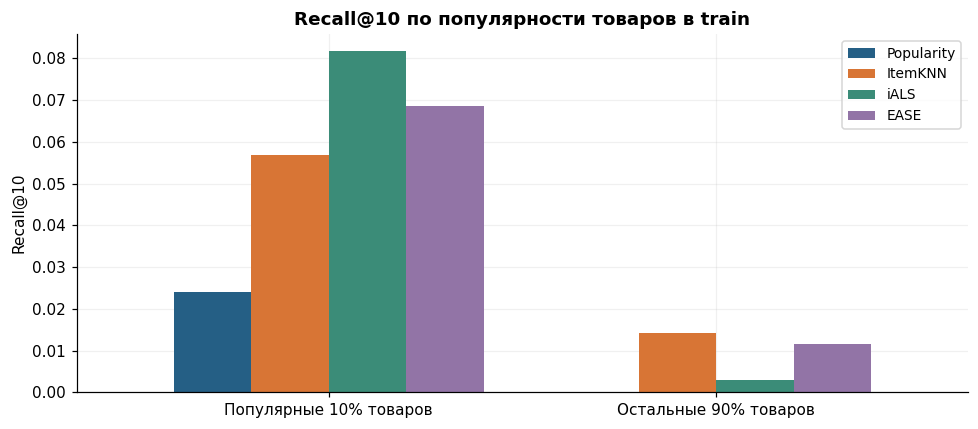

In [38]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(ease_runs['history_slices'])
    display(ease_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
history_order=['1-4','5-9','10+']
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=ease_runs['history_slices'][metric].unstack('model').reindex(history_order)[ease_comparison.model]
    table.plot.bar(ax=ax,color=COLORS[:4],rot=0,width=.8)
    ax.set_title(label+' · длина истории');ax.set_xlabel('Событий в train');ax.set_ylabel(label)
    ax.set_ylim(0,table.to_numpy().max()*1.3)
    ax.legend(fontsize=8,ncol=4,loc='upper center')
show_figure('21_ease_history_slices',fig)
fig,ax=plt.subplots(figsize=(9,4))
item_order=['head_top_10_percent','tail_other_90_percent']
table=ease_runs['popularity_slices'].recall_at_10.unstack('model').reindex(item_order)[ease_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=COLORS[:4],rot=0,width=.8)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10')
ax.legend(fontsize=9)
show_figure('22_ease_popularity_slices',fig)

### 27. Выводы по EASE

In [39]:
ease_m=ease_runs['summary']['best_validation_metrics']
rows=[]
for name in ['ItemKNN','iALS']:
    baseline=ease_runs['summary']['baseline_validation_metrics'][name]
    for metric in ['ndcg_at_10','recall_at_10']:
        interval=ease_intervals[(ease_intervals.baseline==name)&(ease_intervals.metric==metric)&(ease_intervals.estimate_for=='difference')].iloc[0]
        delta=ease_m[metric]-baseline[metric]
        zero='включает ноль' if interval.ci_low<=0<=interval.ci_high else 'не включает ноль'
        rows.append(f"- EASE − {name}, {metric}: {delta:+.6f} ({delta/baseline[metric]:+.2%}); 95% интервал [{interval.ci_low:.6f}; {interval.ci_high:.6f}], {zero}.")
ease_slice=ease_runs['popularity_slices']
head=ease_slice.loc[('EASE','head_top_10_percent'),'recall_at_10']
tail=ease_slice.loc[('EASE','tail_other_90_percent'),'recall_at_10']
boundary=ease_lambda in [min(ease_config['grid']['regularization']),max(ease_config['grid']['regularization'])]
display(Markdown(f"""
Выбрана **λ={ease_lambda:g}**. Validation: **NDCG@10={ease_m['ndcg_at_10']:.6f}, Recall@10={ease_m['recall_at_10']:.6f}**.
Recall head={head:.6f}, tail={tail:.6f}. Матрица весов занимает **{ease_diagnostics['weight_bytes']/2**30:.3f} GiB**.
EASE даёт лучший validation NDCG среди рассмотренных CF/iALS/EASE; цена — плотная матрица.
"""))



Выбрана **λ=100**. Validation: **NDCG@10=0.023372, Recall@10=0.035191**.
Recall head=0.068608, tail=0.011670. Матрица весов занимает **1.808 GiB**.
EASE даёт лучший validation NDCG среди рассмотренных CF/iALS/EASE; цена — плотная матрица.


### 28. Четвёртая модель: Factorization Machine с нуля

[FM второго порядка, Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127):
$$s(x)=w_0+\sum_jw_jx_j+\frac12\sum_f\left[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2\right].$$
Взаимодействуют все активные признаки: user/item ID и временные атрибуты товара.
`models/fm.py`: собственные формула, градиенты и AdaGrad; проверены перебором пар и конечными разностями.

Для item-признаков заранее считаются сумма embedding-векторов $q_i$ и внутренний FM-score $a_i$.
Тогда точный полный score равен $w_0+w_u+a_i+\langle v_u,q_i\rangle$.
Это ускоряет ранжирование всего fit-каталога без приближений и без пересчёта пар отдельно для каждой пары user–item.


### 29. Признаки FM

Правила и масштабы признаков приведены в разделе 6. Календарные токены с менее чем пятью fit-товарами заменены на UNK.
Все исходные timestamps строго раньше запроса. Для финального fit словари и значения пересозданы по train + validation.
Обучение реконструирует fit-метки с признаками на дату запроса; это не последовательное предсказание каждого train-события.


In [40]:
fm_config=json.loads((ROOT/'configs/fm_search.json').read_text())
display(pd.Series(fm_config,name='Зафиксированный план FM').to_frame())


,Зафиксированный план FM
model,FM
grid,"{'n_factors': [16, 32], 'learning_rate': [0.05..."
budget,8
n_epochs,12
batch_size,1024
seed,42
shuffle_seed,43
negative_sampling_seed,137
negatives_per_positive,2
minimum_items_per_metadata_token,5


### 30. Обучающие примеры и фиксированный подбор

Из train: оценки 4–5 дают $y=1$, оценки 1–3 — $y=0$. На каждое положительное событие добавляем
две равномерно выбранные ненаблюдавшиеся пары пользователя с товарами train-каталога.
Выборка с возвращением исключает **все наблюдавшиеся train-пары**, в том числе оценки 1–3;
будущие пары при этом не проверяются. Ненаблюдавшееся — условный отрицательный пример, а не подтверждённая неприязнь.
Выборка фиксируется (seed 137), одинакова между конфигурациями и эпохами. Вероятности не калиброваны.

Оптимизируем среднюю BCE и регуляризацию
$$L=\frac1N\sum_t[\log(1+e^{s_t})-y_ts_t]
 +\frac{\lambda}{2N}\sum_t\sum_j x_{tj}^2(w_j^2+\|v_j\|^2).$$
Регуляризация взвешена частотой и квадратами значений активных признаков; это **не uniform global ridge**.
Bias не регуляризуется. AdaGrad суммирует градиенты повторяющихся feature ID в батче до обновления аккумуляторов.

До первого обучения зафиксированы $f\in\{16,32\}$, learning rate $\in\{0.05,0.15\}$,
$\lambda\in\{10^{-5},10^{-3}\}$: 8 запусков по 12 эпох, batch=1024, init seed=42, shuffle seed=43.
Выбор — NDCG@10 на validation после последней эпохи; ties: меньше факторов, меньше LR, больше регуляризация.
Ранняя остановка не применяется. ID-only ablation обучена при выбранных настройках без отдельного HPO.


In [41]:
fm_runs=load_validation_report(ROOT,'fm')
assert fm_runs['summary']['completed_trials']==8
assert fm_runs['summary']['diagnostic_ablation_runs']==1
assert fm_runs['summary']['test_evaluated'] is False
assert fm_runs['summary']['cohort']['evaluation_users']==10207
fm_search=fm_runs['search'].sort_values(['ndcg_at_10','n_factors','learning_rate','regularization'],ascending=[False,True,True,False]).reset_index(drop=True)
fm_best_params=fm_runs['summary']['best_params']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(fm_search)

,trial,n_factors,learning_rate,regularization,n_epochs,batch_size,seed,shuffle_seed,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,initial_probe_bce,final_probe_bce
0,1,16,0.050000,0.000010,12,1024,42,43,0.005808,0.009718,0.067724,0.000000,10207,1.404772,15.714954,0.614861,0.236961
1,2,16,0.050000,0.001000,12,1024,42,43,0.005391,0.009019,0.063936,0.000000,10207,1.409177,15.803117,0.614861,0.244967
2,5,32,0.050000,0.000010,12,1024,42,43,0.005142,0.008522,0.108871,0.000000,10207,1.424714,26.969359,0.614899,0.153938
3,6,32,0.050000,0.001000,12,1024,42,43,0.005108,0.008271,0.105084,0.000000,10207,1.433897,25.848889,0.614899,0.163465
4,3,16,0.150000,0.000010,12,1024,42,43,0.004346,0.007340,0.142252,0.000000,10207,1.486732,16.349720,0.614861,0.073866
5,7,32,0.150000,0.000010,12,1024,42,43,0.003882,0.006454,0.157337,0.000000,10207,1.553397,26.820102,0.614899,0.016917
6,4,16,0.150000,0.001000,12,1024,42,43,0.003881,0.006399,0.136539,0.000000,10207,1.464162,16.305320,0.614861,0.076154
7,8,32,0.150000,0.001000,12,1024,42,43,0.003559,0.005998,0.159070,0.000000,10207,1.498102,25.829125,0.614899,0.020654


In [42]:
fm_feature_stats=fm_runs['summary']['feature_diagnostics']
fm_training_stats=fm_runs['summary']['training_examples']
display(pd.Series(fm_feature_stats,name='Fit-only признаки').to_frame())
display(pd.Series(fm_training_stats,name='Обучающие примеры').to_frame())

,Fit-only признаки
all_source_timestamps_before_query,True
features,59076
first_month_vocabulary,12
first_year_vocabulary,17
history_age_days_max,"5,923.000"
history_age_days_min,1.000
item_id_features,15578
max_active_item_features,6
max_source_timestamp,1451520000
metadata_assumption,timestamp is event availability; no historical...


,Обучающие примеры
examples,849123
fingerprint,f8a61dd491d22f49683e61e2a63bda288856a3b485758c...
negative_sampling_seed,137
negatives_per_positive,2
observed_negative,71865
observed_positive,259086
sampled_unobserved,518172
sampling,"uniform with replacement, excluding ALL observ..."


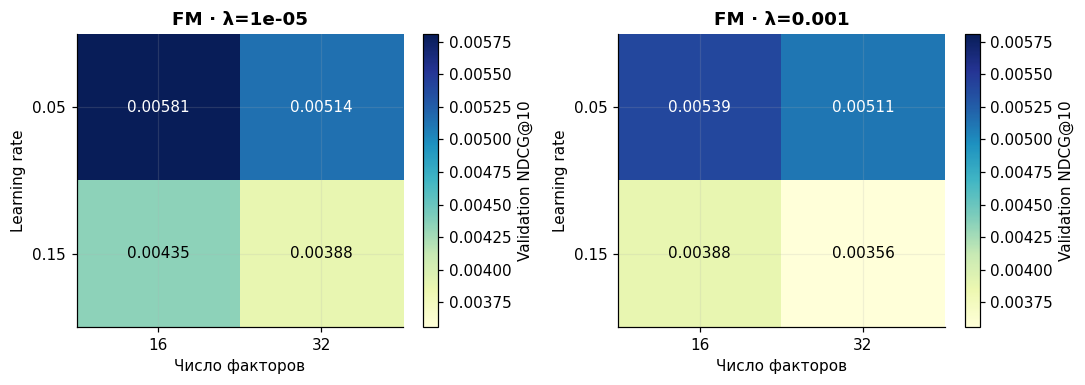

In [43]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
lo=fm_search.ndcg_at_10.min();hi=fm_search.ndcg_at_10.max()
for ax,reg in zip(axes,fm_config['grid']['regularization']):
    table=fm_search[fm_search.regularization==reg].pivot(index='learning_rate',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=lo,vmax=hi,aspect='auto')
    ax.set_xticks(range(len(table.columns)),table.columns);ax.set_yticks(range(len(table.index)),table.index)
    ax.set_xlabel('Число факторов');ax.set_ylabel('Learning rate');ax.set_title(f'FM · λ={reg:g}')
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            value=table.iloc[i,j]
            ax.text(j,i,f'{value:.5f}',ha='center',va='center',color='white' if value>(lo+hi)/2 else 'black')
    fig.colorbar(im,ax=ax,label='Validation NDCG@10')
show_figure('23_fm_hyperparameters',fig)

### 31. Оптимизация FM

BCE и objective посчитаны после эпохи на фиксированных 8 192 train-примерах (seed=991).
`online_objective` — среднее по батчам до обновлений. Монотонность AdaGrad не гарантируется.
Эпоха не выбиралась по этим кривым; критерий подбора — validation NDCG.


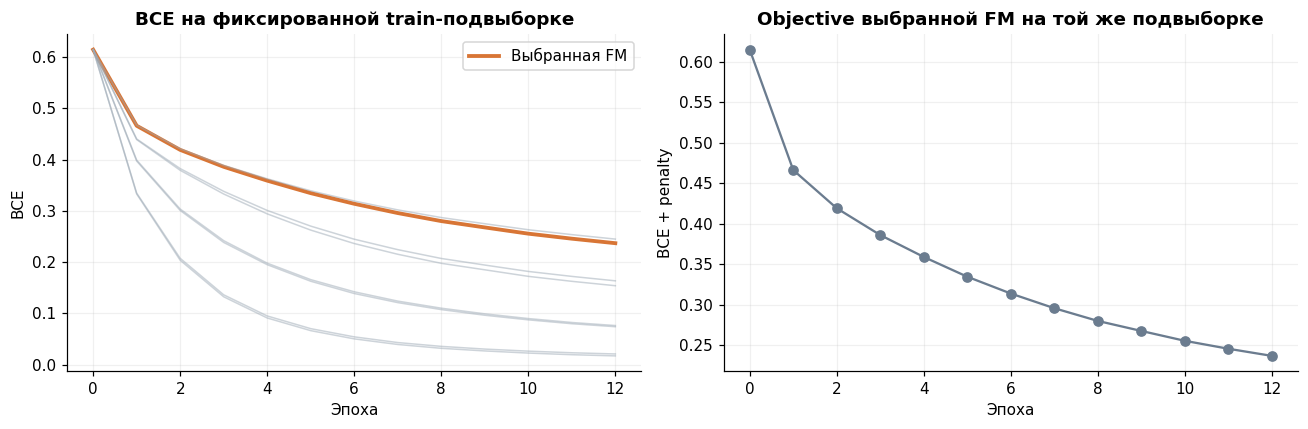

In [44]:
fm_curves=fm_runs['curve'];fm_best_trial=int(fm_search.iloc[0].trial)
assert all(len(g)==13 and g.epoch.tolist()==list(range(13)) for _,g in fm_curves.groupby('trial'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for trial,g in fm_curves.groupby('trial'):
    winner=trial==fm_best_trial
    axes[0].plot(g.epoch,g.probe_bce,color=COLORS[1] if winner else '#9CA9B5',alpha=1 if winner else .5,lw=2.5 if winner else 1,label='Выбранная FM' if winner else None)
best_curve=fm_curves[fm_curves.trial==fm_best_trial]
axes[1].plot(best_curve.epoch,best_curve.probe_objective,marker='o',color=COLORS[4])
axes[0].set_title('BCE на фиксированной train-подвыборке');axes[0].set_ylabel('BCE');axes[0].legend()
axes[1].set_title('Objective выбранной FM на той же подвыборке');axes[1].set_ylabel('BCE + penalty')
for ax in axes:ax.set_xlabel('Эпоха')
show_figure('24_fm_training',fig)

### 32. Сравнение FM и вклад метаданных

Когорта, кандидаты и маски общие. FM обучается и на оценках 1–3, поэтому может персонализировать пользователей без положительной истории.
ID-only ablation использует выбранные настройки; отдельного подбора для неё нет.
Время FM не включает построение признаков и negative sampling.


,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118
4,FM,0.067724,1.404772,0.000000,0.005808,0.009718,10207,15.714954


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,FM,0.005808,0.004964,0.006671
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,-0.015304,-0.017345,-0.013301
3,ItemKNN,recall_at_10,FM,0.009718,0.008164,0.011281
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,-0.022461,-0.025554,-0.019299
6,iALS,ndcg_at_10,FM,0.005808,0.004964,0.006671
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,-0.016086,-0.018080,-0.014071
9,iALS,recall_at_10,FM,0.009718,0.008164,0.011281


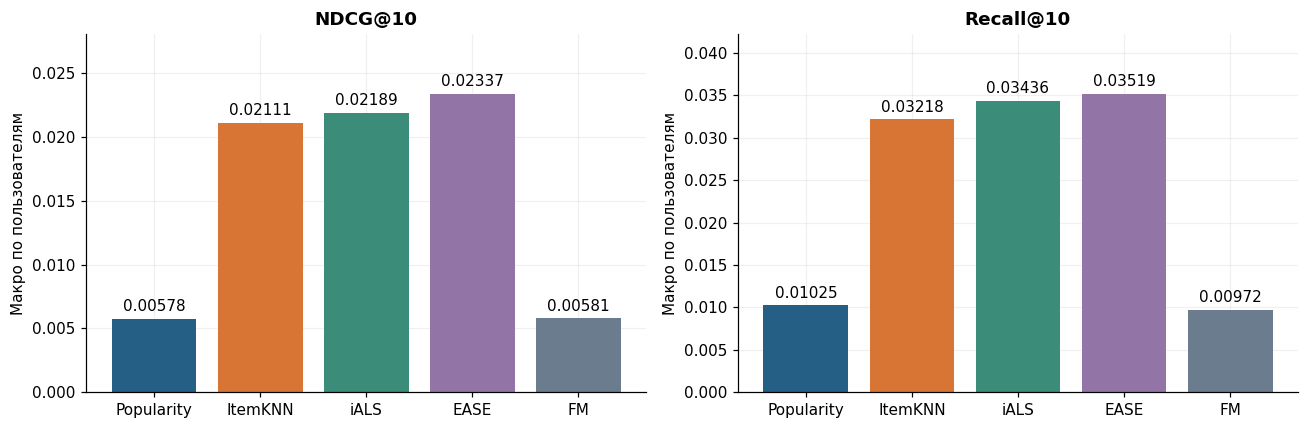

In [45]:
fm_comparison=fm_runs['comparison'];fm_intervals=fm_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(fm_comparison)
    display(fm_intervals)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(fm_comparison.model,fm_comparison[metric],color=COLORS)
    for i,value in enumerate(fm_comparison[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,fm_comparison[metric].max()*1.2);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('25_fm_comparison',fig)

,features,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
0,IDs + dated item metadata,0.005808,0.009718,0.067724,0.000000,10207,1.404772,15.714954
1,IDs only (diagnostic),0.005860,0.008941,0.079214,0.000000,10207,1.507779,7.064159


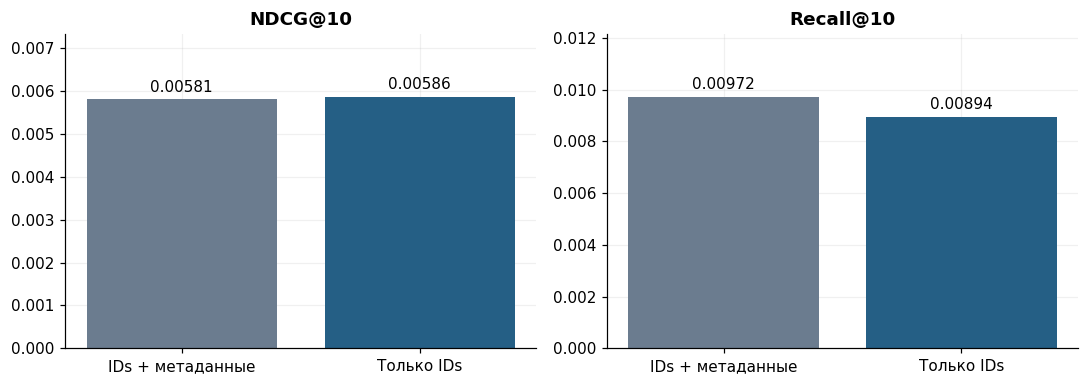

In [46]:
fm_ablation=fm_runs['ablation']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):display(fm_ablation)
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(['IDs + метаданные','Только IDs'],fm_ablation[metric],color=[COLORS[4],COLORS[0]])
    for i,value in enumerate(fm_ablation[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,fm_ablation[metric].max()*1.25);ax.set_title(label)
show_figure('26_fm_metadata_ablation',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000
FM         1-4             5943 0.005964 0.009215       0.000000
           5-9             2766 0.006578 0.012553       0.000000
           10+             1498 0.003767 0.006481       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670
FM         head_top_10_percent     5704                  10248      0.022631
           tail_other_90_percent   7765                  15398      0.000064

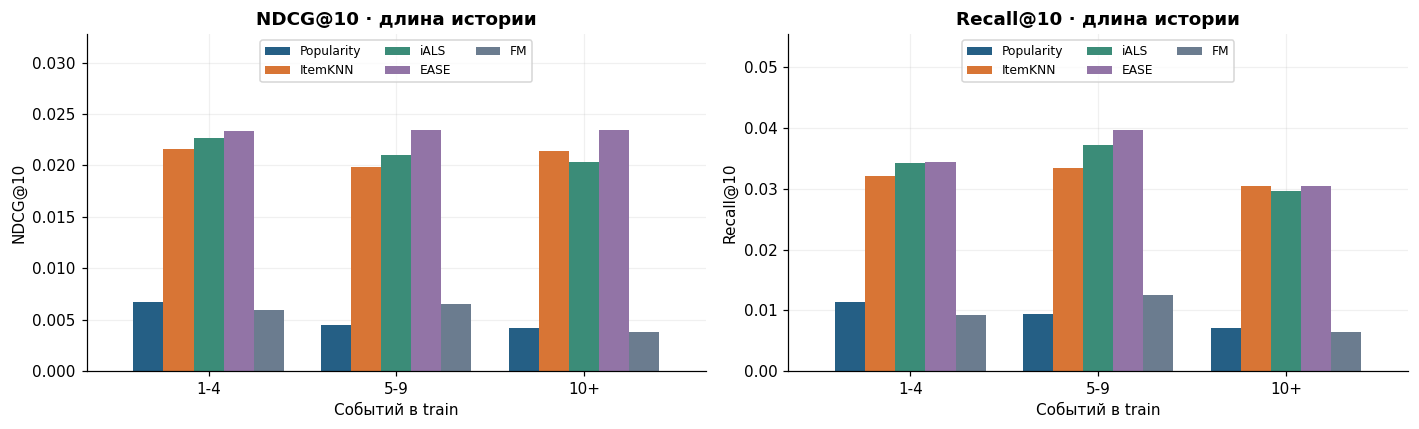

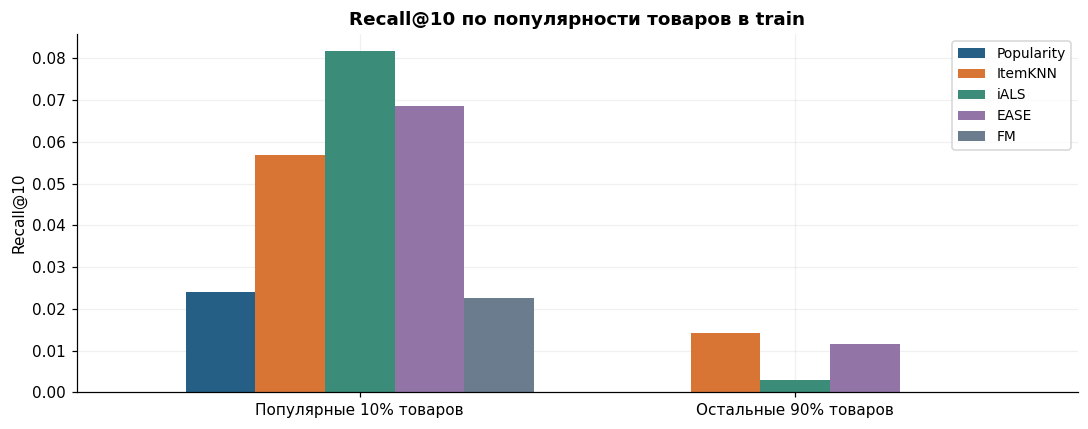

In [47]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(fm_runs['history_slices']);display(fm_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=fm_runs['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[fm_comparison.model]
    table.plot.bar(ax=ax,color=COLORS,rot=0,width=.8)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · длина истории');ax.set_ylabel(label);ax.set_xlabel('Событий в train')
show_figure('27_fm_history_slices',fig)
fig,ax=plt.subplots(figsize=(10,4))
table=fm_runs['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[fm_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=COLORS,rot=0,width=.8)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('28_fm_popularity_slices',fig)

### 33. Выводы по FM

In [48]:
fm_m=fm_runs['summary']['best_validation_metrics']
fm_order=fm_comparison[fm_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False).model.tolist()
fm_place=fm_order.index('FM')+1
fm_lines=[]
for name in ['ItemKNN','iALS','EASE','FM-ID-only']:
    row=fm_intervals[(fm_intervals.baseline==name)&(fm_intervals.metric=='ndcg_at_10')&(fm_intervals.estimate_for=='difference')].iloc[0]
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    fm_lines.append(f'- FM − {name}, NDCG: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
fm_head=fm_runs['popularity_slices'].loc[('FM','head_top_10_percent'),'recall_at_10']
fm_tail=fm_runs['popularity_slices'].loc[('FM','tail_other_90_percent'),'recall_at_10']
fm_id=fm_runs['summary']['id_only_validation_metrics']
display(Markdown(f"""
Выбраны **f={fm_best_params['n_factors']}, LR={fm_best_params['learning_rate']:g}, λ={fm_best_params['regularization']:g}**.
Validation: **NDCG@10={fm_m['ndcg_at_10']:.6f}, Recall@10={fm_m['recall_at_10']:.6f}**; место среди четырёх моделей — {fm_place}.
ID-only: NDCG={fm_id['ndcg_at_10']:.6f}, Recall={fm_id['recall_at_10']:.6f}.
Метапризнаки повысили Recall, но не NDCG при тех же настройках.
Coverage={fm_m['catalog_coverage_at_10']:.2%}; Recall head={fm_head:.6f}, tail={fm_tail:.6f}.
Ограничения: pointwise BCE, условные negatives, 12 эпох и один seed.
"""))



Выбраны **f=16, LR=0.05, λ=1e-05**.
Validation: **NDCG@10=0.005808, Recall@10=0.009718**; место среди четырёх моделей — 4.
ID-only: NDCG=0.005860, Recall=0.008941.
Метапризнаки повысили Recall, но не NDCG при тех же настройках.
Coverage=6.77%; Recall head=0.022631, tail=0.000064.
Ограничения: pointwise BCE, условные negatives, 12 эпох и один seed.


### 34. Пятая модель: timeSVD++ с нуля

Реализована модель [Koren (2009), уравнения 6, 9, 13, 14](https://cseweb.ucsd.edu/classes/fa17/cse291-b/reading/p447-koren.pdf):
$$\hat r_{ui}(t)=\mu+b_i+b_{i,bin(t)}+b_u+\alpha_u dev_u(t)+b_{u,t}
+q_i^\top\left[p_u+a_u dev_u(t)+p_{u,t}+|N_u|^{-1/2}\sum_{j\in N_u}y_j\right].$$
Здесь $N_u$ — **все оценённые товары train**, включая оценки 1–3;
$\mu$ — средняя оценка train. $b_{u,t}$ и $p_{u,t}$ относятся к паре пользователь–UTC-день.
Есть как неявная часть SVD++, так и временные смещения и временные пользовательские факторы.

`models/timesvdpp.py`: собственный полный градиент и AdaGrad на NumPy/SciPy.
Цель — рейтинги 1–5; история включает все fit-товары. Нормированная матрица истории $H$ используется для $HY$ и обратного градиента $H^Tg$.
История включает target, как в offline SVD++; прогнозы не обрезаются.


### 35. Время будущего запроса

$dev_u(t)=sign((t-\bar t_u)/365.25)|(t-\bar t_u)/365.25|^{0.4}$, где $\bar t_u$ — средний train-день, время измеряется в годах.
Item-bins равномерны между крайними днями train; будущий запрос использует последний bin.
Для неизвестной пары user–day локальные bias/factor равны нулю. Дрейф пользователя экстраполируется.
Validation-запрос: 2016-01-01, без дат будущих отзывов. Пользовательский bias не меняет порядок товаров в одном запросе.


In [49]:
time_config=json.loads((ROOT/'configs/timesvdpp_search.json').read_text())
TIME_COLORS=COLORS+['#B04D55']
display(pd.Series(time_config,name='Зафиксированный план timeSVD++').to_frame())


,Зафиксированный план timeSVD++
model,timeSVD++
grid,"{'n_factors': [16, 32], 'n_bins': [12, 36], 'r..."
budget,8
learning_rate,0.050
n_epochs,50
beta,0.400
seed,42
target,original observed ratings 1..5; no negative sa...
implicit_history,"all observed fit items, including the rated ta..."
time,UTC integer Unix days; fit-only per-user mean;...


### 36. Objective и фиксированный подбор

Оптимизируем $\frac1{2N}\sum(r-\hat r)^2$ плюс L2, усреднённую по активным параметрам наблюдений.
Для $b_u,\alpha_u,p_u,a_u$ вес регуляризации равен $n_u/N$, для $b_i,q_i,y_i$ — $n_i/N$;
для item-bin и user-day — их частоты в train, делённые на $N$. Для $Y$ это соответствует
штрафу $\frac1N\sum_u n_u\sum_jH_{uj}^2\|y_j\|^2$. Среднее $\mu$ фиксировано.
Дрейфовые коэффициенты штрафуются как параметры, без дополнительного множителя $dev^2$.
Это частотно-взвешенная L2, не uniform global ridge.

Наш оптимизатор — **full-gradient AdaGrad**: одна эпоха означает один точный шаг по всем train-оценкам.
Это отличается от SGD-оптимизатора оригинальной статьи; воспроизводится prediction-модель, а не её Netflix-результаты.

До первого обучения зафиксированы факторы $\{16,32\}$, bins $\{12,36\}$,
$\lambda\in\{0.01,0.1\}$: 8 конфигураций, 50 шагов, learning rate=0.05, beta=0.4, seed=42.
Выбор по validation NDCG@10 после последнего шага; ties: меньше факторов, меньше bins, больше L2.
Ранняя остановка не применяется. Статическая SVD++ — ablation при выбранных настройках.


In [50]:
time_runs=load_validation_report(ROOT,'timesvdpp')
assert time_runs['summary']['completed_trials']==8
assert time_runs['summary']['diagnostic_ablation_runs']==1
assert time_runs['summary']['test_evaluated'] is False
assert time_runs['summary']['cohort']['evaluation_users']==10207
time_search=time_runs['search'].sort_values(['ndcg_at_10','n_factors','n_bins','regularization'],ascending=[False,True,True,False]).reset_index(drop=True)
time_best_params=time_runs['summary']['best_params']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):display(time_search)

,trial,n_factors,n_bins,regularization,learning_rate,n_epochs,beta,seed,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,initial_training_rmse,final_training_rmse,final_training_objective
0,7,32,36,0.010000,0.050000,50,0.400000,42,0.000616,0.000967,0.338233,0.000000,10207,1.804576,6.674915,1.183779,0.018470,0.011816
1,3,16,36,0.010000,0.050000,50,0.400000,42,0.000567,0.000938,0.263256,0.000000,10207,1.807409,3.809281,1.183765,0.024986,0.012035
2,8,32,36,0.100000,0.050000,50,0.400000,42,0.000381,0.000561,0.181217,0.000000,10207,1.986498,6.735758,1.183779,0.111772,0.080001
3,1,16,12,0.010000,0.050000,50,0.400000,42,0.000380,0.000780,0.298369,0.000000,10207,1.728736,3.704403,1.183765,0.025273,0.012324
4,5,32,12,0.010000,0.050000,50,0.400000,42,0.000364,0.000706,0.397933,0.000000,10207,1.880114,6.909408,1.183779,0.017713,0.012014
5,4,16,36,0.100000,0.050000,50,0.400000,42,0.000279,0.000386,0.177751,0.000000,10207,1.849897,3.889807,1.183765,0.121398,0.080932
6,2,16,12,0.100000,0.050000,50,0.400000,42,0.000135,0.000218,0.218513,0.000000,10207,1.815595,3.674283,1.183765,0.124070,0.083622
7,6,32,12,0.100000,0.050000,50,0.400000,42,0.000123,0.000194,0.244832,0.000000,10207,1.854660,6.732797,1.183779,0.113355,0.082377


,Fit-only время
implicit_history,"all observed fit ratings, including 1-3; targe..."
max_day,16800
mean_rating,4.192
min_day,10878
observed_ratings,330951
user_day_pairs,204153


,Время запроса и параметры
items_without_fit_observations_in_query_bin,"7,044.000"
n_bins,36.000
parameter_bytes,"89,431,880.000"
query_bin,35.000
query_day,"16,801.000"
query_deviation_max,2.953
query_deviation_median,1.068
query_deviation_min,0.094
query_user_day_unseen,"10,207.000"


,Разреженность дневных эффектов (train)
user_day_pairs,"204,153.000"
fraction_user_days_with_one_rating,0.748


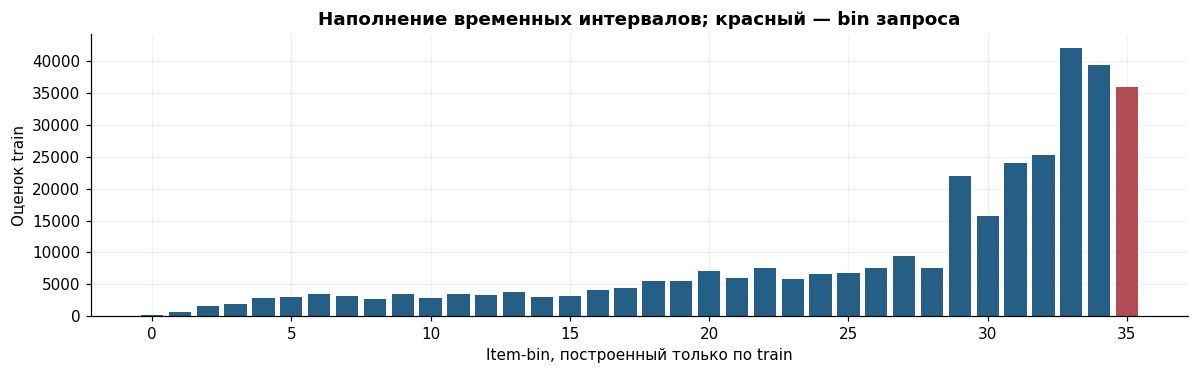

In [51]:
time_diagnostics=time_runs['summary']['best_temporal_diagnostics']
display(pd.Series(time_runs['summary']['time_statistics'],name='Fit-only время').to_frame())
display(pd.Series({k:v for k,v in time_diagnostics.items() if k!='fit_bin_counts'},name='Время запроса и параметры').to_frame())
day_stats=json.loads((ROOT/'reports/presentation_diagnostics.json').read_text())
one_rating_day_share=day_stats['fraction_user_days_with_one_rating']
display(pd.Series(day_stats,name='Разреженность дневных эффектов (train)').to_frame())
fig,ax=plt.subplots(figsize=(11,3.5))
counts=time_diagnostics['fit_bin_counts'];colors=[COLORS[0]]*len(counts);colors[time_diagnostics['query_bin']]=TIME_COLORS[-1]
ax.bar(range(len(counts)),counts,color=colors)
ax.set_xlabel('Item-bin, построенный только по train');ax.set_ylabel('Оценок train')
ax.set_title('Наполнение временных интервалов; красный — bin запроса')
show_figure('29_timesvdpp_time_bins',fig)

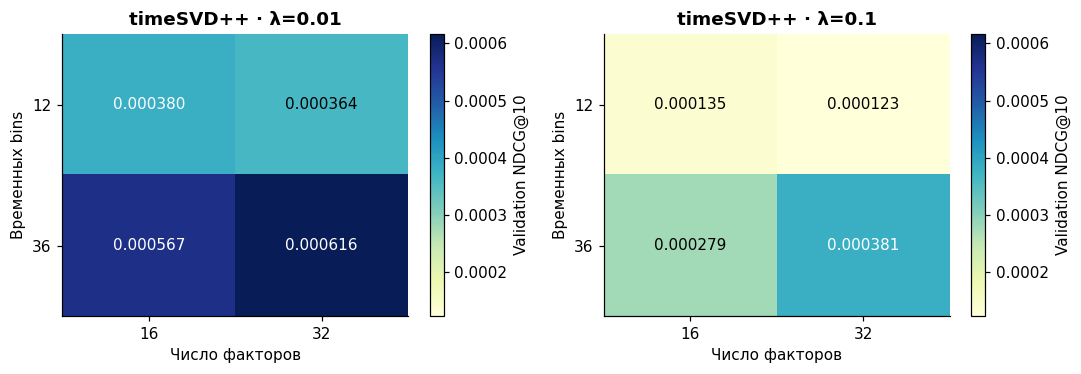

In [52]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5));lo=time_search.ndcg_at_10.min();hi=time_search.ndcg_at_10.max()
for ax,reg in zip(axes,time_config['grid']['regularization']):
    table=time_search[time_search.regularization==reg].pivot(index='n_bins',columns='n_factors',values='ndcg_at_10').sort_index()
    im=ax.imshow(table.values,cmap='YlGnBu',vmin=lo,vmax=hi,aspect='auto');ax.grid(False)
    ax.set_xticks(range(len(table.columns)),table.columns);ax.set_yticks(range(len(table.index)),table.index)
    ax.set_xlabel('Число факторов');ax.set_ylabel('Временных bins');ax.set_title(f'timeSVD++ · λ={reg:g}')
    for i in range(len(table.index)):
        for j in range(len(table.columns)):
            value=table.iloc[i,j];ax.text(j,i,f'{value:.6f}',ha='center',va='center',color='white' if value>(lo+hi)/2 else 'black')
    fig.colorbar(im,ax=ax,label='Validation NDCG@10')
show_figure('30_timesvdpp_hyperparameters',fig)

### 37. Оптимизация timeSVD++

RMSE и objective пересчитаны по всему train после каждого шага.
Дневные параметры дают высокую ёмкость на train, но недоступны для нового дня запроса.
Низкий train RMSE не гарантирует хорошее top-10. Ранняя остановка не применяется.


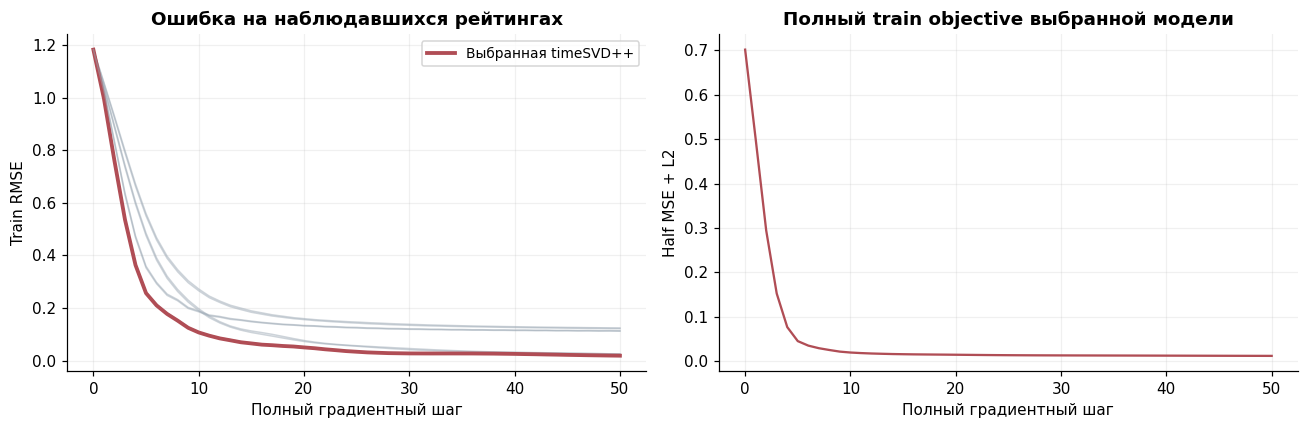

In [53]:
time_curve=time_runs['curve'];time_best_trial=int(time_search.iloc[0].trial)
assert all(len(g)==51 and g.epoch.tolist()==list(range(51)) for _,g in time_curve.groupby('trial'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for trial,g in time_curve.groupby('trial'):
    winner=trial==time_best_trial
    axes[0].plot(g.epoch,g.training_rmse,color=TIME_COLORS[-1] if winner else '#9CA9B5',alpha=1 if winner else .5,lw=2.5 if winner else 1,label='Выбранная timeSVD++' if winner else None)
g=time_curve[time_curve.trial==time_best_trial]
axes[1].plot(g.epoch,g.training_objective,color=TIME_COLORS[-1])
axes[0].set_ylabel('Train RMSE');axes[0].set_title('Ошибка на наблюдавшихся рейтингах');axes[0].legend(fontsize=9)
axes[1].set_ylabel('Half MSE + L2');axes[1].set_title('Полный train objective выбранной модели')
for ax in axes:ax.set_xlabel('Полный градиентный шаг')
show_figure('31_timesvdpp_training',fig)

### 38. Пять моделей на validation

Общий протокол и когорта. Статическая SVD++ отключает временные параметры при тех же настройках;
это диагностическая ablation без отдельного подбора. Интервалы после HPO описательные.


,model,catalog_coverage_at_10,evaluation_seconds,fallback_rate,ndcg_at_10,recall_at_10,users,fit_seconds
0,Popularity,0.000963,1.224501,0.000000,0.005779,0.010252,10207,0.000000
1,ItemKNN,0.738798,1.277437,0.051435,0.021111,0.032179,10207,0.337878
2,iALS,0.143215,1.582736,0.050260,0.021893,0.034360,10207,44.419219
3,EASE,0.497689,1.705730,0.051435,0.023372,0.035191,10207,18.140118
4,FM,0.067724,1.404772,0.000000,0.005808,0.009718,10207,15.714954
5,timeSVD++,0.338233,1.804576,0.000000,0.000616,0.000967,10207,6.674915


,baseline,metric,estimate_for,estimate,ci_low,ci_high
0,ItemKNN,ndcg_at_10,timeSVD++,0.000616,0.000360,0.000945
1,ItemKNN,ndcg_at_10,ItemKNN,0.021111,0.019287,0.023026
2,ItemKNN,ndcg_at_10,difference,-0.020495,-0.022420,-0.018688
3,ItemKNN,recall_at_10,timeSVD++,0.000967,0.000541,0.001514
4,ItemKNN,recall_at_10,ItemKNN,0.032179,0.029379,0.035092
5,ItemKNN,recall_at_10,difference,-0.031212,-0.034128,-0.028370
6,iALS,ndcg_at_10,timeSVD++,0.000616,0.000360,0.000945
7,iALS,ndcg_at_10,iALS,0.021893,0.020066,0.023882
8,iALS,ndcg_at_10,difference,-0.021277,-0.023310,-0.019418
9,iALS,recall_at_10,timeSVD++,0.000967,0.000541,0.001514


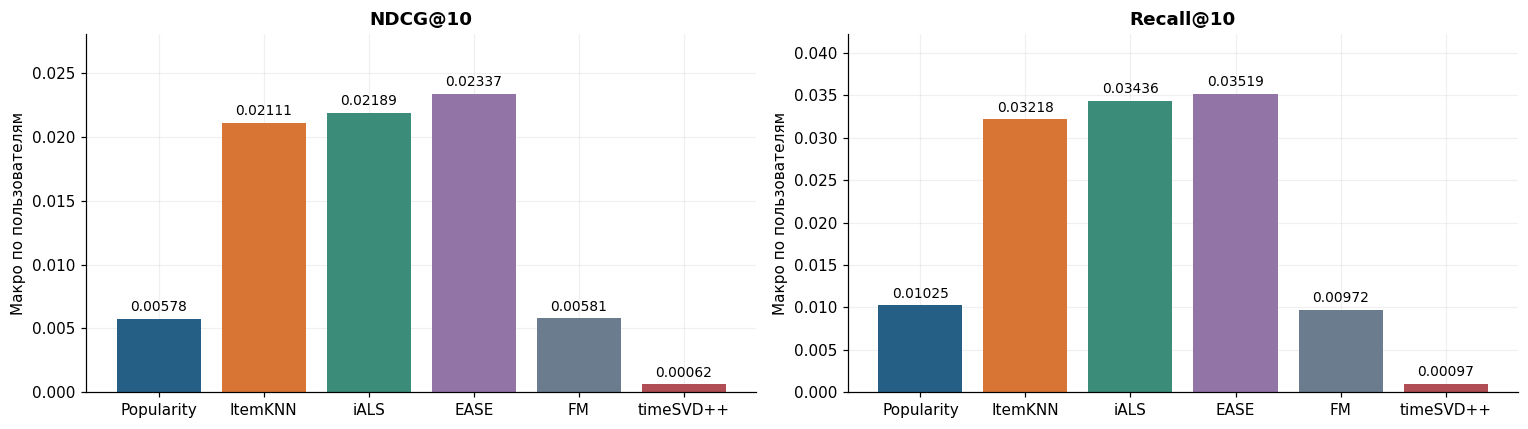

In [54]:
time_comparison=time_runs['comparison'];time_intervals=time_runs['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(time_comparison);display(time_intervals)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(time_comparison.model,time_comparison[metric],color=TIME_COLORS)
    for i,value in enumerate(time_comparison[metric]):ax.annotate(f'{value:.5f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center',fontsize=9)
    ax.set_ylim(0,time_comparison[metric].max()*1.2);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('32_timesvdpp_all_models',fig)

,model,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds
0,timeSVD++,0.000616,0.000967,0.338233,0.000000,10207,1.804576,6.674915
1,SVD++ static (diagnostic),0.001193,0.002038,0.473552,0.000000,10207,1.731394,4.755733


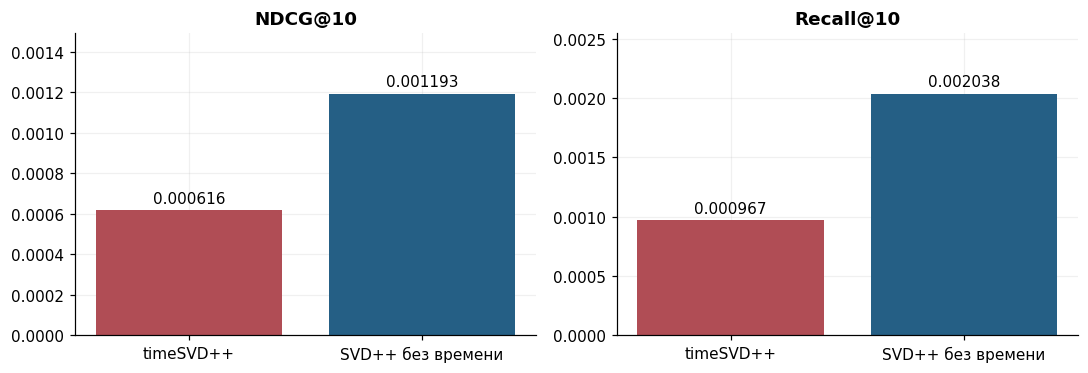

In [55]:
time_ablation=time_runs['ablation']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):display(time_ablation)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    ax.bar(['timeSVD++','SVD++ без времени'],time_ablation[metric],color=[TIME_COLORS[-1],COLORS[0]])
    for i,value in enumerate(time_ablation[metric]):ax.annotate(f'{value:.6f}',(i,value),xytext=(0,5),textcoords='offset points',ha='center')
    ax.set_ylim(0,time_ablation[metric].max()*1.25);ax.set_title(label)
show_figure('33_timesvdpp_temporal_ablation',fig)

users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             5943 0.006765 0.011434       0.000000
           5-9             2766 0.004511 0.009421       0.000000
           10+             1498 0.004205 0.007094       0.000000
ItemKNN    1-4             5943 0.021634 0.032072       0.086152
           5-9             2766 0.019806 0.033355       0.004700
           10+             1498 0.021447 0.030435       0.000000
iALS       1-4             5943 0.022691 0.034203       0.084133
           5-9             2766 0.021001 0.037281       0.004700
           10+             1498 0.020377 0.029589       0.000000
EASE       1-4             5943 0.023352 0.034353       0.086152
           5-9             2766 0.023400 0.039595       0.004700
           10+             1498 0.023397 0.030388       0.000000
FM         1-4             5943 0.005964 0.009215       0.000000
           5-9             2766 0.006578 0.012553       0.000000
           10+             1498 0.003767 0.006481       0.000000
timeSVD++  1-4             5943 0.000488 0.000787       0.000000
           5-9             2766 0.000872 0.001265       0.000000
           10+             1498 0.000653 0.001135       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5704                  10248      0.024125
           tail_other_90_percent   7765                  15398      0.000000
ItemKNN    head_top_10_percent     5704                  10248      0.056922
           tail_other_90_percent   7765                  15398      0.014238
iALS       head_top_10_percent     5704                  10248      0.081696
           tail_other_90_percent   7765                  15398      0.002851
EASE       head_top_10_percent     5704                  10248      0.068608
           tail_other_90_percent   7765                  15398      0.011670
FM         head_top_10_percent     5704                  10248      0.022631
           tail_other_90_percent   7765                  15398      0.000064
timeSVD++  head_top_10_percent     5704                  10248      0.001624
           tail_other_90_percent   7765                  15398      0.000558

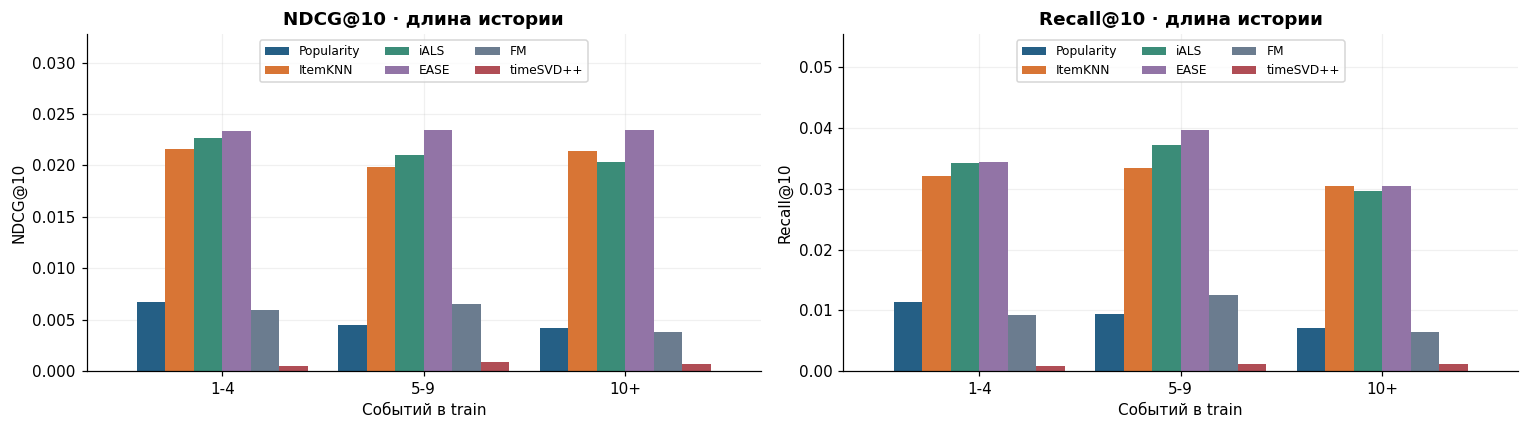

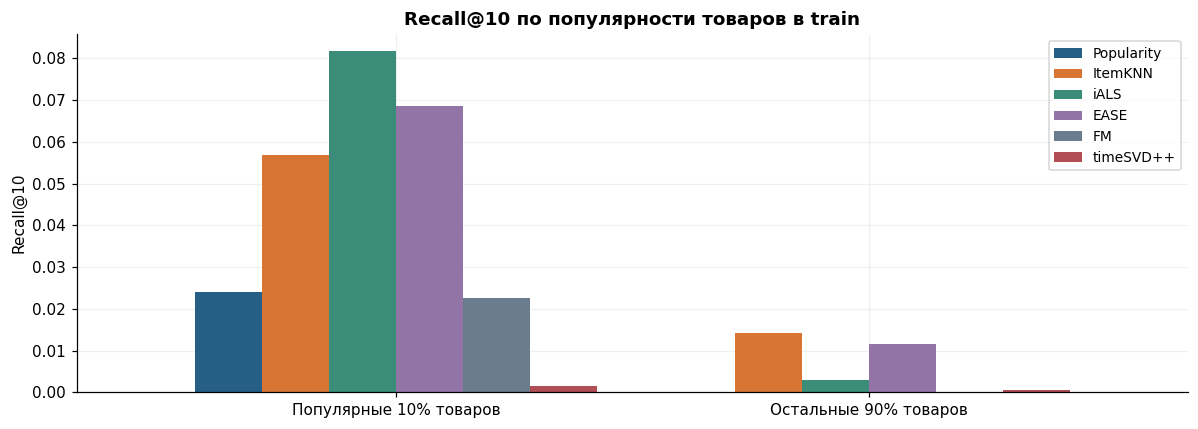

In [56]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(time_runs['history_slices']);display(time_runs['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['NDCG@10','Recall@10']):
    table=time_runs['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[time_comparison.model]
    table.plot.bar(ax=ax,color=TIME_COLORS,rot=0,width=.85)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · длина истории');ax.set_xlabel('Событий в train');ax.set_ylabel(label)
show_figure('34_timesvdpp_history_slices',fig)
fig,ax=plt.subplots(figsize=(11,4))
table=time_runs['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[time_comparison.model]
table.index=['Популярные 10% товаров','Остальные 90% товаров']
table.plot.bar(ax=ax,color=TIME_COLORS,rot=0,width=.85)
ax.set_title('Recall@10 по популярности товаров в train');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('35_timesvdpp_popularity_slices',fig)

### 39. Выводы по timeSVD++ и текущему сравнению

In [57]:
time_m=time_runs['summary']['best_validation_metrics'];static_m=time_runs['summary']['static_validation_metrics']
model_order=time_comparison[time_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False).model.tolist()
time_place=model_order.index('timeSVD++')+1;time_lines=[]
for name in ['ItemKNN','iALS','EASE','FM','SVD++ static']:
    row=time_intervals[(time_intervals.baseline==name)&(time_intervals.metric=='ndcg_at_10')&(time_intervals.estimate_for=='difference')].iloc[0]
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    time_lines.append(f'- timeSVD++ − {name}, NDCG: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
rmse=float(time_search.iloc[0].final_training_rmse)
display(Markdown(f"""
Выбраны **f={time_best_params['n_factors']}, bins={time_best_params['n_bins']}, λ={time_best_params['regularization']:g}**.
Validation: **NDCG@10={time_m['ndcg_at_10']:.6f}, Recall@10={time_m['recall_at_10']:.6f}**; место — {time_place} из пяти.
Статическая SVD++: NDCG={static_m['ndcg_at_10']:.6f}, Recall={static_m['recall_at_10']:.6f}; временная часть не улучшила ranking.
Train RMSE={rmse:.6f}. В {one_rating_day_share:.2%} user-day пар одна оценка; локальные дневные параметры на день запроса неизвестны.
Возможные причины слабого top-N: рейтинговый objective, ёмкость дневных параметров и экстраполяция. Их отдельный вклад не установлен.
"""))



Выбраны **f=32, bins=36, λ=0.01**.
Validation: **NDCG@10=0.000616, Recall@10=0.000967**; место — 5 из пяти.
Статическая SVD++: NDCG=0.001193, Recall=0.002038; временная часть не улучшила ranking.
Train RMSE=0.018470. В 74.77% user-day пар одна оценка; локальные дневные параметры на день запроса неизвестны.
Возможные причины слабого top-N: рейтинговый objective, ёмкость дневных параметров и экстраполяция. Их отдельный вклад не установлен.


### 40. Фиксация настроек и финальная оценка

`configs/final_models.json` фиксирует лучшие validation-настройки. Все пять моделей заново обучены на train + validation;
test открыт после завершения пяти fit. После оценки v2 параметры и признаки не менялись.

**Test ранее использовался в v1.** V2 исправляет историческую доступность признаков FM;
это повторная оценка прежнего holdout. Независимая [оценка за 2019 год](external_2019/experiments.ipynb) оформлена отдельно.
Полный пересчёт запускается через `scripts/reproduce.py` в новой папке.


In [58]:
final=load_final_report(ROOT)
final_summary=final['summary']
final_lock=json.loads((ROOT/'configs/final_models.json').read_text())
assert final_summary['completed_refits']==5
assert final_summary['completed_test_evaluations']==6  # 5 models and popularity control
assert final_summary['test_evaluated'] is True
assert final_summary['models']==final_lock['models']
FINAL_COLORS=COLORS+['#B04D55']

In [59]:
display(pd.DataFrame([{'model':name,**params} for name,params in final_lock['models'].items()]).set_index('model'))
refit_rows=[]
for name,info in final_summary['refit_manifest'].items():
    refit_rows.append({'model':name,'fit_seconds':info['fit_seconds'],'fit_fingerprint_matches':info['fit_fingerprint']==final_summary['fit_fingerprint']})
display(pd.DataFrame(refit_rows).set_index('model'))
display(pd.Series(final_summary['refit_manifest']['FM']['diagnostics'],name='FM: новый препроцессинг по train+validation').to_frame())
training_diagnostics=[]
for name,curve in final['training_curves'].items():
    last=curve.iloc[-1]
    training_diagnostics.append({'model':name,**{k:float(last[k]) for k in ['objective','probe_bce','training_rmse','training_objective'] if k in last}})
display(pd.DataFrame(training_diagnostics).set_index('model'))

,regularization,batch_size,learning_rate,n_epochs,n_factors,seed,...,shrinkage,alpha,n_iterations,solver_batch_size,beta,n_bins
model,,,,,,,,,,,,,
EASE,100.000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN
FM,0.000,"1,024.000",0.050,12.000,16.000,42.000,...,NaN,NaN,NaN,NaN,NaN,NaN
ItemKNN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.000,NaN,NaN,NaN,NaN,NaN
iALS,0.100,NaN,NaN,NaN,64.000,42.000,...,NaN,40.000,15.000,128.000,NaN,NaN
timeSVD++,0.010,NaN,0.050,50.000,32.000,42.000,...,NaN,NaN,NaN,NaN,0.400,36.000


,fit_seconds,fit_fingerprint_matches
model,,
EASE,22.052,True
FM,20.080,True
ItemKNN,0.431,True
iALS,50.805,True
timeSVD++,8.286,True


,FM: новый препроцессинг по train+validation
feature_diagnostics,"{'all_source_timestamps_before_query': True, '..."
feature_fingerprint,90191f32da8fefb30a87cc30df5035a4e2d0d564cfcf22...
preparation_seconds,0.990
training_examples,"{'examples': 1041411, 'fingerprint': 'd7e649cb..."


,objective,probe_bce,training_rmse,training_objective
model,,,,
iALS,"6,254,222.619",NaN,NaN,NaN
FM,NaN,0.235,NaN,NaN
timeSVD++,NaN,NaN,0.019,0.012


### 41. Финальный fit

Индексы, веса, признаки FM и временная схема timeSVD++ построены заново по train + validation.
Запрос: 2017-01-01 UTC. История заморожена, все известные товары исключены.
Оценка относится к общей warm-start когорте. Ограничения отбора 5-core и snapshot-названия сохраняются.


In [60]:
final_protocol=json.loads((ROOT/'reports/evaluation_protocol.json').read_text())
final_scope=final_protocol['evaluation_diagnostics']['test']
display(pd.Series(final_summary['fit'],name='Финальное обучение').to_frame())
display(pd.Series(final_summary['cohort'],name='Общая test-когорта').to_frame())
display(pd.Series({
    'test_events':final_summary['test_rows'],
    'all_positive_test_events':final_scope['all_positive_interactions'],
    'available_relevant_test_events':final_summary['cohort']['relevant_interactions'],
    'positive_event_coverage':final_scope['positive_interaction_coverage'],
    'query_utc':str(pd.Timestamp(final_summary['query_timestamp'],unit='s',tz='UTC')),
    'validation_reference':final_summary['validation_reference']},name='Область оценки').to_frame())
assert final_summary['cohort']['evaluation_users']==9521
assert final_summary['cohort']['catalog_items']==16721
assert final_summary['cohort']['relevant_interactions']==23454

,Финальное обучение
interactions,403681
items,16721
max_timestamp,1483142400
users,48349


,Общая test-когорта
catalog_items,16721
evaluation_users,9521
new_item_interactions,4423
new_user_interactions,16023
relevant_interactions,23454
seen_relevant_items_removed,0
users_excluded_for_fewer_than_k_candidates,0


,Область оценки
test_events,49308
all_positive_test_events,40470
available_relevant_test_events,23454
positive_event_coverage,0.580
query_utc,2017-01-01 00:00:00+00:00
validation_reference,EASE


### 42. Итоговое сравнение

Reference EASE выбрана по validation. Парные 95% bootstrap-интервалы: 2 000 повторов, seed=42.
Они не учитывают вариацию обучения между seeds и множественные сравнения.
Fit-время исключает индексацию и специальный препроцессинг FM/timeSVD++.


,model,ndcg_at_10,recall_at_10,catalog_coverage_at_10,fallback_rate,users,evaluation_seconds,fit_seconds,selected_parameters
0,Popularity,0.009712,0.012274,0.001076,0.000000,9521,1.464656,0.000000,{}
1,ItemKNN,0.021241,0.032328,0.674242,0.034030,9521,1.251584,0.430743,"{""n_neighbors"": 100, ""shrinkage"": 10.0}"
2,iALS,0.022217,0.034842,0.135040,0.033295,9521,1.696599,50.804966,"{""alpha"": 40.0, ""n_factors"": 64, ""n_iterations..."
3,EASE,0.022048,0.033390,0.442378,0.034030,9521,1.922433,22.052107,"{""regularization"": 100.0}"
4,FM,0.006611,0.010603,0.067699,0.000000,9521,1.477249,20.080308,"{""batch_size"": 1024, ""learning_rate"": 0.05, ""n..."
5,timeSVD++,0.000579,0.001113,0.348185,0.000000,9521,1.712942,8.286376,"{""beta"": 0.4, ""learning_rate"": 0.05, ""n_bins"":..."


,comparison,metric,estimate_for,estimate,ci_low,ci_high
2,Popularity - EASE,ndcg_at_10,difference,-0.012336,-0.014643,-0.009981
5,Popularity - EASE,recall_at_10,difference,-0.021116,-0.024299,-0.017868
8,ItemKNN - EASE,ndcg_at_10,difference,-0.000807,-0.001768,0.000217
11,ItemKNN - EASE,recall_at_10,difference,-0.001062,-0.002773,0.000774
14,iALS - EASE,ndcg_at_10,difference,0.000169,-0.001465,0.001961
17,iALS - EASE,recall_at_10,difference,0.001452,-0.001359,0.004324
20,FM - EASE,ndcg_at_10,difference,-0.015436,-0.017508,-0.013404
23,FM - EASE,recall_at_10,difference,-0.022787,-0.025950,-0.019790
26,timeSVD++ - EASE,ndcg_at_10,difference,-0.021469,-0.023387,-0.019520
29,timeSVD++ - EASE,recall_at_10,difference,-0.032277,-0.035190,-0.029425


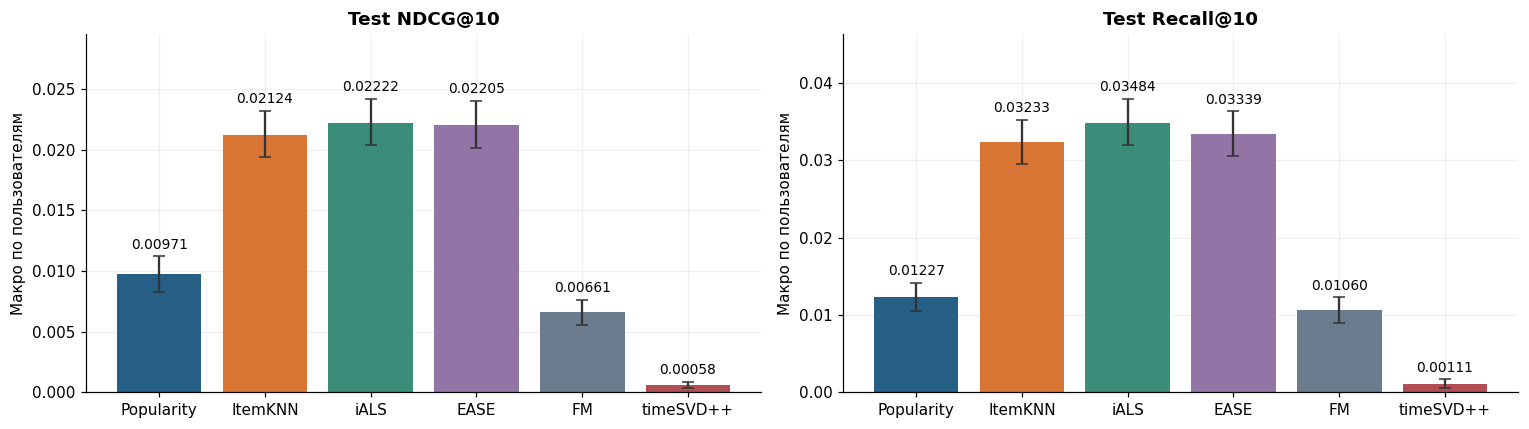

In [61]:
final_comparison=final['comparison'];final_intervals=final['intervals']
with pd.option_context('display.float_format',lambda x:f'{x:.6f}','display.max_columns',None):
    display(final_comparison.assign(selected_parameters=final_comparison.model.map(lambda name: json.dumps(final_lock['models'].get(name,{}),ensure_ascii=False,sort_keys=True))))
    display(final_intervals[final_intervals.estimate_for=='difference'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['Test NDCG@10','Test Recall@10']):
    ax.bar(final_comparison.model,final_comparison[metric],color=FINAL_COLORS)
    tops=[]
    for i,row in final_comparison.iterrows():
        ci=final_intervals[(final_intervals.metric==metric)&(final_intervals.estimate_for==row.model)].iloc[0]
        ax.errorbar(i,row[metric],yerr=[[max(0,row[metric]-ci.ci_low)],[max(0,ci.ci_high-row[metric])]],fmt='none',ecolor='#333333',capsize=4)
        tops.append(ci.ci_high)
        ax.annotate(f'{row[metric]:.5f}',(i,ci.ci_high),xytext=(0,5),textcoords='offset points',ha='center',fontsize=9)
    ax.set_ylim(0,max(tops)*1.22);ax.set_title(label);ax.set_ylabel('Макро по пользователям')
show_figure('36_final_test_metrics',fig)

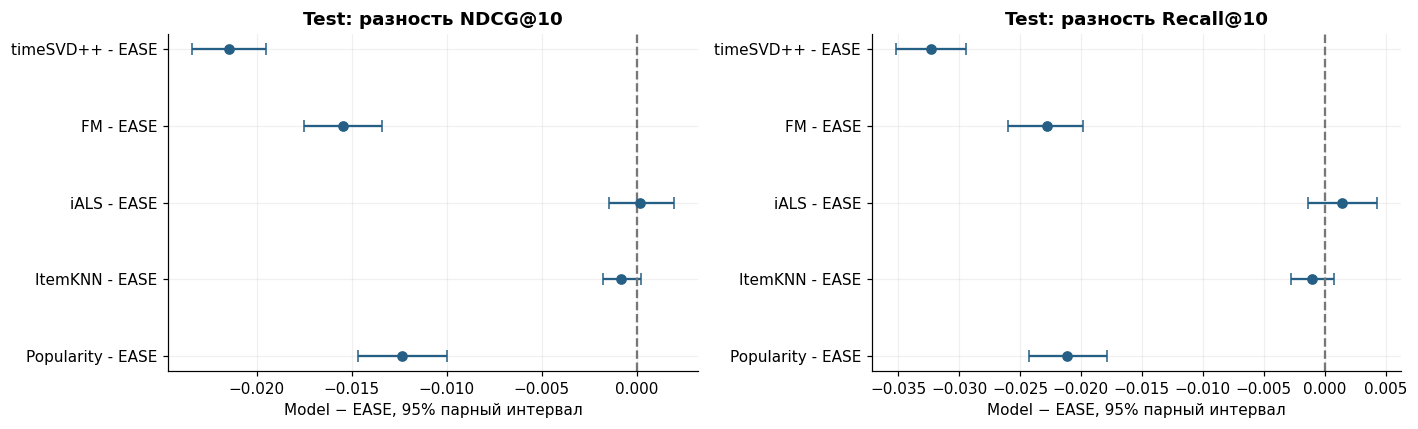

In [62]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    table=final_intervals[(final_intervals.metric==metric)&(final_intervals.estimate_for=='difference')].reset_index(drop=True)
    ax.errorbar(table.estimate,range(len(table)),xerr=[table.estimate-table.ci_low,table.ci_high-table.estimate],fmt='o',capsize=4,color='#255F85')
    ax.axvline(0,color='#777777',ls='--');ax.set_yticks(range(len(table)),table.comparison)
    ax.set_title('Test: разность '+label);ax.set_xlabel('Model − EASE, 95% парный интервал')
show_figure('37_final_paired_differences',fig)

### 43. Validation и test

Различаются веса, когорта, каталог и горизонт: 2016 год против января 2017 — октября 2018.
Разность метрик не является парной оценкой эффекта дополнительного обучения.


,model,metric,validation,test
0,ItemKNN,ndcg_at_10,0.021,0.021
1,ItemKNN,recall_at_10,0.032,0.032
2,ItemKNN,catalog_coverage_at_10,0.739,0.674
3,iALS,ndcg_at_10,0.022,0.022
4,iALS,recall_at_10,0.034,0.035
5,iALS,catalog_coverage_at_10,0.143,0.135
6,EASE,ndcg_at_10,0.023,0.022
7,EASE,recall_at_10,0.035,0.033
8,EASE,catalog_coverage_at_10,0.498,0.442
9,FM,ndcg_at_10,0.006,0.007


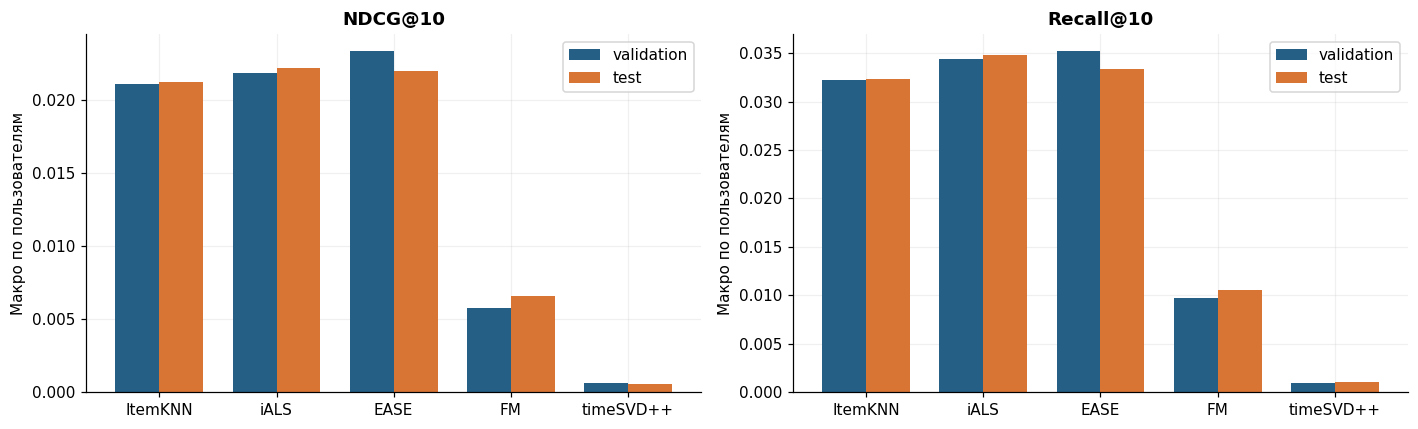

In [63]:
display(final['validation_vs_test'])
fig,axes=plt.subplots(1,2,figsize=(13,4))
order=final_comparison.loc[final_comparison.model!='Popularity','model'].tolist()
for ax,metric,label in zip(axes,['ndcg_at_10','recall_at_10'],['NDCG@10','Recall@10']):
    table=final['validation_vs_test'][final['validation_vs_test'].metric==metric].set_index('model').reindex(order)[['validation','test']]
    table.plot.bar(ax=ax,rot=0,color=[COLORS[0],COLORS[1]],width=.75)
    ax.set_title(label);ax.set_xlabel('');ax.set_ylabel('Макро по пользователям')
show_figure('38_final_validation_vs_test',fig)

### 44. Срезы качества

Истории и head/tail определены по train + validation. Recall среза усреднён по пользователям с релевантными товарами этого среза.
Один пользователь может входить в оба среза. Coverage и fallback дополняют точность.


users     ndcg   recall  fallback_rate
model      history_slice                                        
Popularity 1-4             4561 0.009973 0.012498       0.000000
           5-9             3149 0.008969 0.011169       0.000000
           10+             1811 0.010345 0.013631       0.000000
ItemKNN    1-4             4561 0.023038 0.033194       0.067310
           5-9             3149 0.019291 0.031996       0.005399
           10+             1811 0.020105 0.030724       0.000000
iALS       1-4             4561 0.025259 0.037720       0.065775
           5-9             3149 0.020026 0.033892       0.005399
           10+             1811 0.018363 0.029246       0.000000
EASE       1-4             4561 0.024040 0.033743       0.067310
           5-9             3149 0.020436 0.033490       0.005399
           10+             1811 0.019831 0.032327       0.000000
FM         1-4             4561 0.006794 0.010981       0.000000
           5-9             3149 0.005446 0.008973       0.000000
           10+             1811 0.008176 0.012484       0.000000
timeSVD++  1-4             4561 0.000307 0.000488       0.000000
           5-9             3149 0.000390 0.000926       0.000000
           10+             1811 0.001592 0.003013       0.000000

users  relevant_interactions  recall_at_10
model      item_slice                                                       
Popularity head_top_10_percent     5572                  10028      0.027900
           tail_other_90_percent   7063                  13426      0.000000
ItemKNN    head_top_10_percent     5572                  10028      0.056127
           tail_other_90_percent   7063                  13426      0.013090
iALS       head_top_10_percent     5572                  10028      0.077209
           tail_other_90_percent   7063                  13426      0.002494
EASE       head_top_10_percent     5572                  10028      0.064549
           tail_other_90_percent   7063                  13426      0.009704
FM         head_top_10_percent     5572                  10028      0.025591
           tail_other_90_percent   7063                  13426      0.000203
timeSVD++  head_top_10_percent     5572                  10028      0.001546
           tail_other_90_percent   7063                  13426      0.000549

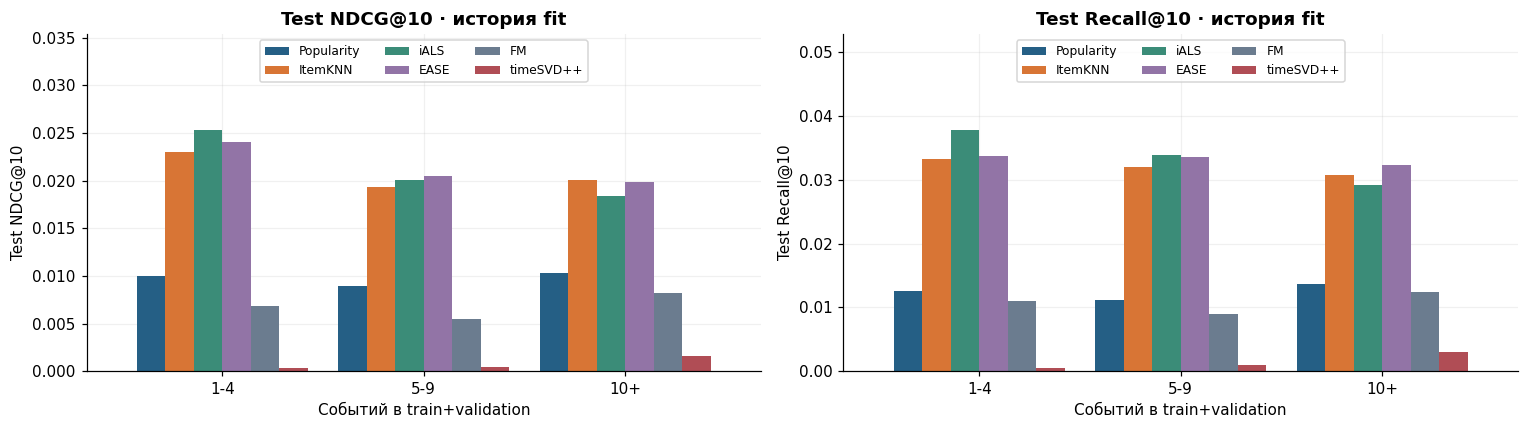

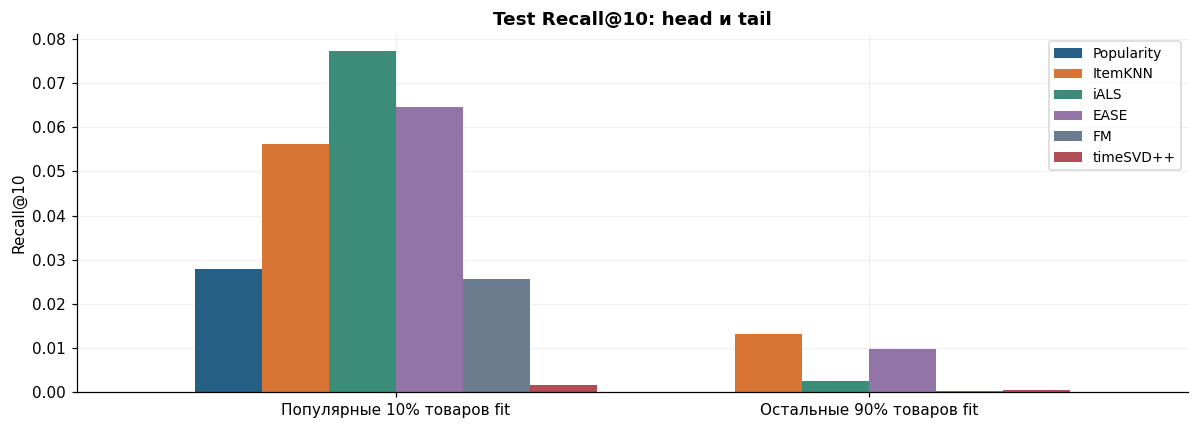

In [64]:
with pd.option_context('display.float_format',lambda x:f'{x:.6f}'):
    display(final['history_slices']);display(final['popularity_slices'])
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric,label in zip(axes,['ndcg','recall'],['Test NDCG@10','Test Recall@10']):
    table=final['history_slices'][metric].unstack('model').reindex(['1-4','5-9','10+'])[final_comparison.model]
    table.plot.bar(ax=ax,color=FINAL_COLORS,rot=0,width=.85)
    ax.set_ylim(0,table.to_numpy().max()*1.4);ax.legend(fontsize=8,ncol=3,loc='upper center')
    ax.set_title(label+' · история fit');ax.set_xlabel('Событий в train+validation');ax.set_ylabel(label)
show_figure('39_final_history_slices',fig)
fig,ax=plt.subplots(figsize=(11,4))
table=final['popularity_slices'].recall_at_10.unstack('model').reindex(['head_top_10_percent','tail_other_90_percent'])[final_comparison.model]
table.index=['Популярные 10% товаров fit','Остальные 90% товаров fit']
table.plot.bar(ax=ax,color=FINAL_COLORS,rot=0,width=.85)
ax.set_title('Test Recall@10: head и tail');ax.set_xlabel('');ax.set_ylabel('Recall@10');ax.legend(fontsize=9)
show_figure('40_final_popularity_slices',fig)

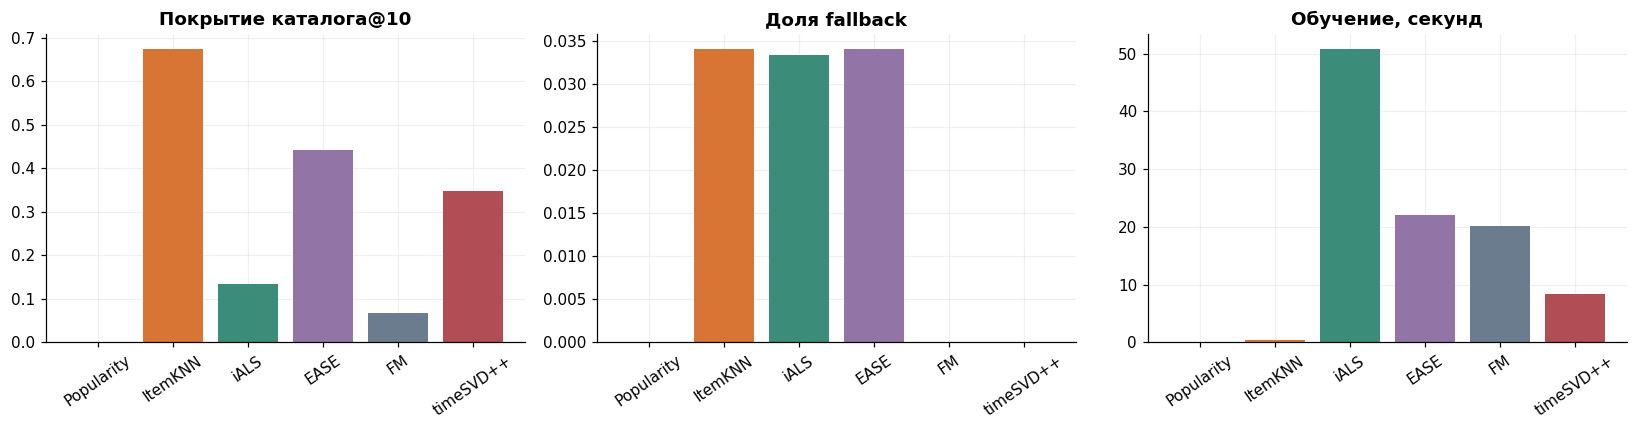

In [65]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric,label in zip(axes,['catalog_coverage_at_10','fallback_rate','fit_seconds'],['Покрытие каталога@10','Доля fallback','Обучение, секунд']):
    ax.bar(final_comparison.model,final_comparison[metric],color=FINAL_COLORS)
    ax.set_title(label);ax.tick_params(axis='x',labelrotation=35)
show_figure('41_final_coverage_fallback_cost',fig)

### 45. Итоговые выводы

In [66]:
final_models=final_comparison[final_comparison.model!='Popularity'].sort_values('ndcg_at_10',ascending=False)
observed_test_leader=final_models.iloc[0]
reference=final_summary['validation_reference']
ref=final_comparison.set_index('model').loc[reference]
final_lines=[]
for _,row in final_intervals[(final_intervals.metric=='ndcg_at_10')&(final_intervals.estimate_for=='difference')].iterrows():
    zero='включает ноль' if row.ci_low<=0<=row.ci_high else 'не включает ноль'
    final_lines.append(f'- {row.comparison}: **{row.estimate:+.6f}**, 95% интервал **[{row.ci_low:.6f}; {row.ci_high:.6f}]**, {zero}.')
tail_table=final['popularity_slices'].recall_at_10.unstack('model')
tail_best=tail_table.loc['tail_other_90_percent'].idxmax()
display(Markdown(f"""
Финальный fit: **{fmt(final_summary['fit']['interactions'])} событий**.
Test-когорта: **{fmt(final_summary['cohort']['evaluation_users'])} пользователей**, охват положительных событий — **{final_scope['positive_interaction_coverage']:.2%}**.

Выбранная по validation **{reference}**: NDCG@10={ref.ndcg_at_10:.6f}, Recall@10={ref.recall_at_10:.6f}.
Точечный test-лидер — **{observed_test_leader.model}** ({observed_test_leader.ndcg_at_10:.6f}).
CI для iALS − EASE включает ноль: надёжное преимущество не установлено. Лучший Recall хвоста — у **{tail_best}**.
FM и timeSVD++ уступают Popularity; низкая train loss не гарантирует хорошее ранжирование.

Ограничения: прежний test уже использовался в v1, full-period 5-core, отбор по snapshot-названию,
исключение cold start, разные горизонты и один seed. Отзывы не равны показам или покупкам.
Метапризнаки FM доступны до запроса. Независимая [оценка за 2019 год](external_2019/experiments.ipynb) проведена с теми же настройками.
"""))



Финальный fit: **403 681 событий**.
Test-когорта: **9 521 пользователей**, охват положительных событий — **57.95%**.

Выбранная по validation **EASE**: NDCG@10=0.022048, Recall@10=0.033390.
Точечный test-лидер — **iALS** (0.022217).
CI для iALS − EASE включает ноль: надёжное преимущество не установлено. Лучший Recall хвоста — у **ItemKNN**.
FM и timeSVD++ уступают Popularity; низкая train loss не гарантирует хорошее ранжирование.

Ограничения: прежний test уже использовался в v1, full-period 5-core, отбор по snapshot-названию,
исключение cold start, разные горизонты и один seed. Отзывы не равны показам или покупкам.
Метапризнаки FM доступны до запроса. Независимая [оценка за 2019 год](external_2019/experiments.ipynb) проведена с теми же настройками.
